# Import

In [1]:
import datetime
import glob
import json
import os
import matplotlib
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statistics
import scipy.stats as stats
import pylandstats as pls
import math
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import cv2 as cv2
from scipy.interpolate import interp1d
from scipy.interpolate import make_interp_spline, BSpline
from matplotlib.lines import Line2D
import networkx as nx
from scipy.spatial import ConvexHull, convex_hull_plot_2d
from scipy import spatial
import alphashape
import pingouin as pg
from collections import Counter
from matplotlib.gridspec import GridSpec
import matplotlib.gridspec as gridspec

import plotly.express as px
import plotly.graph_objects as go

import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
import statsmodels.api as sm

import matplotlib.ticker as mticker

import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering 
from scipy.spatial.distance import pdist, squareform
# import mantel
from ridgeplot import ridgeplot

from pySankey.sankey import sankey

import matplotlib.patches as patches
import matplotlib.collections as collections
import matplotlib.colors as mcolors  # Import Normalize function
import matplotlib.patheffects as pe
from matplotlib.sankey import Sankey

from matplotlib.patches import Arc, RegularPolygon
from numpy import radians as rad

from pathlib import Path
import imageio.v2 as imageio
import time

import itertools

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)


#!! Set working directory !!#
userpath='C:/Users/peter/Documents/GitHub/HoneybeeNestMorphogenesis'
os.chdir(userpath)


colony_names = ['DD1', 'DD2', 'DD4', 'DD5', 'DD6', 'DD7', 'SH2', 'SH3', 'SH4', 'SH5', 'SH6', 'SH7']
contentcolors = [(0/255, 0/255, 0/255), #background
             (166/255, 32/255, 64/255), #wood
             (64/255, 64/255, 128/255), #empty_comb
             (96/255, 96/255, 191/255), #eggs
             (128/255, 128/255, 255/255), #larvae
             (159/255, 159/255, 119/255), #pupae
             (191/255, 191/255, 14/255), #pollen
             (223/255, 223/255, 135/255), #nectar
             (255/255, 255/255, 255/255), #honey
             ]
contenthex = ['#000000', #background
             '#a62040', #wood
             '#404080', #empty_comb
             '#6060bf', #eggs
             '#8080ff', #larvae
             '#9f9f77', #pupae
             '#bfbf0e', #pollen
             '#dfdf87', #nectar
             '#ffffff', #honey
             ]
simplehex = [
             '#1f998a', #any_brood
             '#67cc5c', #pollen
             '#34618d', #nectar_honey
             ]
treatmenthex = [
                '#31688e', #DD
                '#35b779', #SH
                ]
# treatmenthex = [
#                 'lightblue', #DD
#                 'lightgreen', #SH
#                 ]

# inside the frame 6:-4,6:-6]
xmincrop = 6
xmaxcrop = -6
ymincrop = 6
ymaxcrop = -4


## Import masks

In [2]:
### Contents, Downsample 48, all weeks

content_names = [
 'background',
 'wood',
 'empty_comb',
 'eggs',
 'larvae',
 'pupae',
 'pollen',
 'nectar',
 'honey',
 'queen_cup',
 'queen_cell',
 'bees',
]
short_names = content_names[:9]

# Load contents array
#using aligned
Contents = np.load('CombMasks_Contents_aligned.npy', allow_pickle=True) 

# Load cropped contents array
#using aligned
ContentsCrop = np.load('CombMasks_Contents_crop.npy', allow_pickle=True) 

# count the number of masks
mask_count = 0
for c in range(len(Contents)):
    count = len(Contents[c]) * 20 # number of weeks for that colony multiplied by the number of frames per week (20)
    mask_count += count
print(f'Total number of masks: {mask_count}')


Total number of masks: 4720


In [3]:
# pixel to cm conversion factor
within_frame_width_cm = 43
within_frame_width_px = ContentsCrop[0][0][0].shape[1]
px_to_cm_factor = within_frame_width_cm / within_frame_width_px
px_to_cm_factor

0.48863636363636365

In [4]:
# Simplified Content array

simple_names = [
 'background',
 'empty_comb',
 'any_brood',
 'pollen',
 'nectar_honey',
]

# Load contents array
ContentsSimple = np.load('CombMasks_Contents_simple.npy', allow_pickle=True) 


In [5]:
### Comb types, Downsample 48, all weeks

combtype_names = [
    'background', 
    'wood', 
    'worker', 
    'drone', 
    'queen', 
    'bee',
]
class_names = combtype_names

# Load comb type array
CombType = np.load('CombMasks_CombTypes_aligned.npy', allow_pickle=True) 

In [6]:
### Combined, Downsample 48, all weeks

combined_names = [
 'background',
 'wood',
 'worker_empty_comb',
 'worker_eggs',
 'worker_larvae',
 'worker_pupae',
 'worker_pollen',
 'worker_nectar',
 'worker_honey',
 'queen_cup',
 'queen_cell',
 'bees',
 'drone_empty_comb',
 'drone_eggs',
 'drone_larvae',
 'drone_pupae',
 'drone_pollen',
 'drone_nectar',
 'drone_honey',
]
class_names = combined_names

# Load combined array
Combined = np.load('CombMasks_Combined_aligned.npy', allow_pickle=True) 

## Import dataframes

In [7]:
df_mergedinsp = pd.read_csv('df_combcounts.csv')

df_mergedinsp['perc_bees_onframe'] = df_mergedinsp['bees_onframe']/df_mergedinsp['bees_sum_perweek']

df_mergedinsp['nectar_honey'] =  df_mergedinsp[['nectar','honey']].sum(axis=1) # this should be calculated in Contents_make (but need to be at lab to access D drive)
df_mergedinsp['perc_nectar_honey'] =  (df_mergedinsp['nectar_honey']/df_mergedinsp['totalcomb'])*100 # this should be calculated in Contents_make (but need to be at lab to access D drive)
df_mergedinsp['comb_perim_area_ratio'] =  df_mergedinsp['comb_perim']/(np.sqrt(df_mergedinsp['totalcomb'])) # circle = 3.54, 2:1 rectangle = 4.24. this should be calculated in Contents_make (but need to be at lab to access D drive)

df_mergedinsp['frame_RO'] = 11 - df_mergedinsp['frame']
df_mergedinsp.loc[(df_mergedinsp['colony']=='DD6')|(df_mergedinsp['colony']=='DD7')|(df_mergedinsp['colony']=='SH4'), 'frame_RO'] = df_mergedinsp['frame']

colony_deadout_week = [23, 17, 25, 31, 32, 33, 35, 37, 40] # These are true_weeks where the photos are of the combs after the colony died. Can be filtered out with data = df_mergedinsp[~df_mergedinsp.true_week.isin(colony_deadout_week)]

df_mergedinsp.head(25)

,colony,date,week,true_week,frame,side,treatment,background,wood,empty_comb,eggs,larvae,pupae,pollen,nectar,honey,queen_cup,queen_cell,bees,all_comb_centroidX,all_comb_centroidY,empty_comb_centroidX,empty_comb_centroidY,eggs_centroidX,eggs_centroidY,larvae_centroidX,larvae_centroidY,pupae_centroidX,pupae_centroidY,pollen_centroidX,pollen_centroidY,nectar_centroidX,nectar_centroidY,honey_centroidX,honey_centroidY,nectar_honey,totalcomb,perc_empty_comb,perc_eggs,perc_larvae,perc_pupae,perc_pollen,perc_nectar,perc_honey,perc_allbrood,perc_nectar_honey,primary_content,perc_primary_content,primary_content_combinebrood,perc_primary_content_combinebrood,worker_empty_comb,worker_eggs,worker_larvae,worker_pupae,worker_pollen,worker_nectar,worker_honey,drone_empty_comb,drone_eggs,drone_larvae,drone_pupae,drone_pollen,drone_nectar,drone_honey,worker_empty_comb_centroidX,worker_empty_comb_centroidY,worker_eggs_centroidX,worker_eggs_centroidY,worker_larvae_centroidX,worker_larvae_centroidY,worker_pupae_centroidX,worker_pupae_centroidY,worker_pollen_centroidX,worker_pollen_centroidY,worker_nectar_centroidX,worker_nectar_centroidY,worker_honey_centroidX,worker_honey_centroidY,queen_cup_centroidX,queen_cup_centroidY,queen_cell_centroidX,queen_cell_centroidY,bees_centroidX,bees_centroidY,drone_empty_comb_centroidX,drone_empty_comb_centroidY,drone_eggs_centroidX,drone_eggs_centroidY,drone_larvae_centroidX,drone_larvae_centroidY,drone_pupae_centroidX,drone_pupae_centroidY,drone_pollen_centroidX,drone_pollen_centroidY,drone_nectar_centroidX,drone_nectar_centroidY,drone_honey_centroidX,drone_honey_centroidY,worker_allbrood,drone_allbrood,allbrood,totalworkercomb,totaldronecomb,perc_totalworkercomb,perc_totaldronecomb,perc_worker_allbrood,perc_worker_eggs,perc_worker_larvae,perc_worker_pupae,perc_worker_pollen,perc_worker_nectar,perc_worker_honey,perc_drone_allbrood,perc_drone_eggs,perc_drone_larvae,perc_drone_pupae,perc_drone_pollen,perc_drone_nectar,perc_drone_honey,perc_dronebrood_allbrood,primary_content_combtypes,perc_primary_content_combtypes,primary_content_combinebrood_combtypes,perc_primary_content_combinebrood_combtypes,empty_space,date_formatted,filename,exp_date,ncombs,centX,centY,rmaxid,rmaxpos,rmax,width,cmaxid,cmaxpos,cmax,height,aspecthw,perim,area,perarea,centX2,centY2,rmaxid2,rmaxpos2,rmax2,width2,cmaxid2,cmaxpos2,cmax2,height2,aspecthw2,perim2,area2,perarea2,areagrowth,area2growth,QR,position,invert_frame,bees_sum,comb_sq,comb_sum,comb_cm2,core_position,frame_unique,bees_onframe,bees_sum_perweek,first_comb_frame,bees_percombcm2,combcm2_perbee,nframes_with_comb,comb_birthday,comb_age,comb_sum_perweek,avg_comb_perframe,comb_prop_ttl,birthday_nestsize,nestarea_seasontotal,prop_area_seasontotal,comb_growth,combcm2_growth,comb_growth_prop,combcm2_lastweek,emptyspace_onframe,framesfromfirst,initial_region,comb_cm2_neibL,comb_cm2_neibR,comb_cm2_neib_avg,bees_neibL,bees_neibR,bees_neib_avg,n_comb_neibs,2_comb_neibs,bi_2_comb_neibs,nest_edge,nest_edge_triplet,last_pos,next_pos,last_neibR,last_neibR_combcm2,last_neibL,last_neibL_combcm2,last_neibBigger_comb,last_neibSmaller_comb,last_neib_combavg,this_neibR,this_neibR_combcm2,this_neibL,this_neibL_combcm2,this_neibBigger_comb,this_neibSmaller_comb,this_neib_combavg,neighborhood_change,next_neibR,next_neibR_combcm2,next_neibL,next_neibL_combcm2,next_neibBigger_comb,next_neibSmaller_comb,next_neib_combavg,days_since_last_insp,nestheight,nestheight2,nestheightperc,nestwidth,nestwidth2,nestwidthperc,frameaspecthw,nestaspecthw,nestdepth,nestdepthperc,nestarea,nestarea2,nestareaperc,nestareagrowth,nestarea2growth,nestcentX,nestcentX2,nestcentY,nestcentY2,rmaxsum,nestcentZprep,Zweight,nestcentZ,initialN,initialE,initialQ,initialQl,comb_width,comb_height,comb_perim,comb_aspecthw,seasonal_phase,seasonal_phase_num,total_area,number_of_patches,patch_density,largest_patch_index,total_edge,edge_density,total_core_area,number_of_disjunct_core_areas,landscape_shape_index,effective_mesh_size,entropy,shann

In [8]:
# Cell neighbors

df_cellneib = pd.read_csv('df_cellneib.csv')
df_cellneib

,colony,date,true_week,week,frame,side,framenum,focalcontent,nfocalcells,neibcontent,percniebcontent_onframe,neibperc,perc_diff,frame_reoriented,seasonal_phase,treatment
0,DD1,20210412,1,1,5,a,8,eggs,125,background,NaN,0.0,NaN,6,spring_growth,DD
1,DD1,20210412,1,1,5,a,8,eggs,125,wood,NaN,0.0,NaN,6,spring_growth,DD
2,DD1,20210412,1,1,5,a,8,eggs,125,empty_comb,71.284271,43.3,-27.984271,6,spring_growth,DD
3,DD1,20210412,1,1,5,a,8,eggs,125,eggs,18.037518,55.8,37.762482,6,spring_growth,DD
4,DD1,20210412,1,1,5,a,8,eggs,125,larvae,1.010101,0.8,-0.210101,6,spring_growth,DD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239551,SH7,20210930,25,18,10,b,19,nectar,2,nectar,0.060588,0.0,-0.060588,1,fall_flow,SH
239552,SH7,20210930,25,18,10,b,19,nectar,2,honey,0.000000,0.0,NaN,1,fall_flow,SH
239553,SH7,20210930,25,18,10,b,19,nectar,2,queen_cup,0.000000,0.0,NaN,1,fall_flow,SH
239554,SH7,20210930,25,18,10,b,19,nectar,2,queen_cell,0.000000,0.0,NaN,1,fall_flow,SH


In [9]:
# Cell future self

df_cellfuture = pd.read_csv('df_cellfuture.csv')
df_cellfuture

,colony,date,true_week,week,frame,side,framenum,focalcontent,nfocalcells,nextself,nextselfcount,nextperc,frame_reoriented,seasonal_phase,treatment
0,DD1,20210412,1,1,5,a,8,empty_comb,494,empty_comb,149,30.161943,6,spring_growth,DD
1,DD1,20210412,1,1,5,a,8,empty_comb,494,eggs,9,1.821862,6,spring_growth,DD
2,DD1,20210412,1,1,5,a,8,empty_comb,494,larvae,245,49.595142,6,spring_growth,DD
3,DD1,20210412,1,1,5,a,8,empty_comb,494,pupae,0,0.000000,6,spring_growth,DD
4,DD1,20210412,1,1,5,a,8,empty_comb,494,pollen,3,0.607287,6,spring_growth,DD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163690,SH7,20210923,24,17,10,b,19,nectar,1,larvae,0,0.000000,1,fall_flow,SH
163691,SH7,20210923,24,17,10,b,19,nectar,1,pupae,0,0.000000,1,fall_flow,SH
163692,SH7,20210923,24,17,10,b,19,nectar,1,pollen,1,100.000000,1,fall_flow,SH
163693,SH7,20210923,24,17,10,b,19,nectar,1,nectar,0,0.000000,1,fall_flow,SH


In [10]:
# Cluster metric (nearest neighbor)

# Comb-level
df_nearestdist = pd.read_csv('df_nearestdist.csv')
df_nearestdist_sum = pd.read_csv('df_nearestdist_sum.csv')

# Nest level (3D)
df_nearestdist_nest = pd.read_csv('df_nearestdist_nest.csv')
df_nearestdist_nest_sum = pd.read_csv('df_nearestdist_nest_sum.csv')

# add dispersion metric column to df_mergedinsp
df_mergedinsp = df_mergedinsp.merge(df_nearestdist_sum, how='left', on=['colony', 'treatment', 'date','week', 'true_week', 'frame', 'side']) 
df_mergedinsp = df_mergedinsp.merge(df_nearestdist_nest_sum, how='left', on=['colony', 'treatment', 'date','week', 'true_week']) 
df_mergedinsp.rename(columns={'dispersion_metric_x':'dispersion_metric',
                              'dispersion_metric_y':'dispersion_metric_nest'}, inplace=True) 

df_mergedinsp

,colony,date,week,true_week,frame,side,treatment,background,wood,empty_comb,eggs,larvae,pupae,pollen,nectar,honey,queen_cup,queen_cell,bees,all_comb_centroidX,all_comb_centroidY,empty_comb_centroidX,empty_comb_centroidY,eggs_centroidX,eggs_centroidY,larvae_centroidX,larvae_centroidY,pupae_centroidX,pupae_centroidY,pollen_centroidX,pollen_centroidY,nectar_centroidX,nectar_centroidY,honey_centroidX,honey_centroidY,nectar_honey,totalcomb,perc_empty_comb,perc_eggs,perc_larvae,perc_pupae,perc_pollen,perc_nectar,perc_honey,perc_allbrood,perc_nectar_honey,primary_content,perc_primary_content,primary_content_combinebrood,perc_primary_content_combinebrood,worker_empty_comb,worker_eggs,worker_larvae,worker_pupae,worker_pollen,worker_nectar,worker_honey,drone_empty_comb,drone_eggs,drone_larvae,drone_pupae,drone_pollen,drone_nectar,drone_honey,worker_empty_comb_centroidX,worker_empty_comb_centroidY,worker_eggs_centroidX,worker_eggs_centroidY,worker_larvae_centroidX,worker_larvae_centroidY,worker_pupae_centroidX,worker_pupae_centroidY,worker_pollen_centroidX,worker_pollen_centroidY,worker_nectar_centroidX,worker_nectar_centroidY,worker_honey_centroidX,worker_honey_centroidY,queen_cup_centroidX,queen_cup_centroidY,queen_cell_centroidX,queen_cell_centroidY,bees_centroidX,bees_centroidY,drone_empty_comb_centroidX,drone_empty_comb_centroidY,drone_eggs_centroidX,drone_eggs_centroidY,drone_larvae_centroidX,drone_larvae_centroidY,drone_pupae_centroidX,drone_pupae_centroidY,drone_pollen_centroidX,drone_pollen_centroidY,drone_nectar_centroidX,drone_nectar_centroidY,drone_honey_centroidX,drone_honey_centroidY,worker_allbrood,drone_allbrood,allbrood,totalworkercomb,totaldronecomb,perc_totalworkercomb,perc_totaldronecomb,perc_worker_allbrood,perc_worker_eggs,perc_worker_larvae,perc_worker_pupae,perc_worker_pollen,perc_worker_nectar,perc_worker_honey,perc_drone_allbrood,perc_drone_eggs,perc_drone_larvae,perc_drone_pupae,perc_drone_pollen,perc_drone_nectar,perc_drone_honey,perc_dronebrood_allbrood,primary_content_combtypes,perc_primary_content_combtypes,primary_content_combinebrood_combtypes,perc_primary_content_combinebrood_combtypes,empty_space,date_formatted,filename,exp_date,ncombs,centX,centY,rmaxid,rmaxpos,rmax,width,cmaxid,cmaxpos,cmax,height,aspecthw,perim,area,perarea,centX2,centY2,rmaxid2,rmaxpos2,rmax2,width2,cmaxid2,cmaxpos2,cmax2,height2,aspecthw2,perim2,area2,perarea2,areagrowth,area2growth,QR,position,invert_frame,bees_sum,comb_sq,comb_sum,comb_cm2,core_position,frame_unique,bees_onframe,bees_sum_perweek,first_comb_frame,bees_percombcm2,combcm2_perbee,nframes_with_comb,comb_birthday,comb_age,comb_sum_perweek,avg_comb_perframe,comb_prop_ttl,birthday_nestsize,nestarea_seasontotal,prop_area_seasontotal,comb_growth,combcm2_growth,comb_growth_prop,combcm2_lastweek,emptyspace_onframe,framesfromfirst,initial_region,comb_cm2_neibL,comb_cm2_neibR,comb_cm2_neib_avg,bees_neibL,bees_neibR,bees_neib_avg,n_comb_neibs,2_comb_neibs,bi_2_comb_neibs,nest_edge,nest_edge_triplet,last_pos,next_pos,last_neibR,last_neibR_combcm2,last_neibL,last_neibL_combcm2,last_neibBigger_comb,last_neibSmaller_comb,last_neib_combavg,this_neibR,this_neibR_combcm2,this_neibL,this_neibL_combcm2,this_neibBigger_comb,this_neibSmaller_comb,this_neib_combavg,neighborhood_change,next_neibR,next_neibR_combcm2,next_neibL,next_neibL_combcm2,next_neibBigger_comb,next_neibSmaller_comb,next_neib_combavg,days_since_last_insp,nestheight,nestheight2,nestheightperc,nestwidth,nestwidth2,nestwidthperc,frameaspecthw,nestaspecthw,nestdepth,nestdepthperc,nestarea,nestarea2,nestareaperc,nestareagrowth,nestarea2growth,nestcentX,nestcentX2,nestcentY,nestcentY2,rmaxsum,nestcentZprep,Zweight,nestcentZ,initialN,initialE,initialQ,initialQl,comb_width,comb_height,comb_perim,comb_aspecthw,seasonal_phase,seasonal_phase_num,total_area,number_of_patches,patch_density,largest_patch_index,total_edge,edge_density,total_core_area,number_of_disjunct_core_areas,landscape_shape_index,effective_mesh_size,entropy,shann

## Functions

In [11]:
# round to significant figure for statistical tests

from math import log10, floor
def round_sig(x, sig=2):
    return round(x, sig-int(floor(log10(abs(x))))-1)


def jitter(xlist, amount=0.03):
    randlist = np.random.uniform(size = len(xlist), low = -amount, high = amount)
    return xlist + randlist


def centroid(mask, content):
    coords = np.argwhere(mask==content)
    centroid = np.mean(coords, axis=0)
    return centroid


def flipmasks(masks):
    # flip every other frame in a whole nest masks (takes masks for whole nest at one timepoint)
    flippedmasks = np.copy(masks)
    flippedmasks[1::2, :, :] = flippedmasks[1::2, :, ::-1] #flip every other frame
    return flippedmasks


def shiftmask(mask, hshift=3, vshift=0):
    # single mask shift
    # shift the mask inside the image canvas to align more precisely with other masks

    maskshift = np.copy(mask)

    # horizontal shift
    if hshift>0:
        clip = maskshift[:, :-hshift]
        zeroes = np.zeros((clip.shape[0], hshift))
        maskshift = np.concatenate((zeroes, clip), axis=1)

    # vertical shift
    if vshift>0:
        clip = maskshift[:-vshift, :]
        zeroes = np.zeros((vshift, clip.shape[1]))
        maskshift = np.concatenate((zeroes, clip), axis=0)

    return maskshift



def shiftmasks(masks, hshift=3, vshift=0):
    # shift every other frame in the whole nest mask shift
    # shift the masks inside the image canvas to align more precisely with other masks

    maskshift = np.copy(masks)

    # horizontal shift
    if hshift>0:
        clip = maskshift[1::2, :, :-hshift]
        zeroes = np.zeros((len(clip), clip.shape[1], hshift))
        maskshift[1::2, :, :] = np.concatenate((zeroes, clip), axis=2)

    # vertical shift
    if vshift>0:
        clip = maskshift[1::2, :-vshift, :]
        zeroes = np.zeros((len(clip), vshift, clip.shape[2]))
        maskshift[1::2, :, :] = np.concatenate((zeroes, clip), axis=1)

    return maskshift





def xyz_coords(masks, content_names_toinclude, contents=np.arange(12), zskip=4, flip=True, shift=False):
    '''
    Get xyz coordinates of all cells of specified contents in a 3D nest mask array.
    masks: 3D numpy array of nest (z,y,x), z is frames (should be 20 for full nest)
    content_names_toinclude: list of content names to include
    contents: list or array of content ids to extract coordinates for (default all 0-11)
    zskip: spacing between z layers (default 4, for downsampled 48)
    flip: whether to flip every other frame (default True)
    shift: whether to shift every other frame (default False)
    '''
    
    customz=[[0,0]]
    for n in range(10):
        n=customz[-1][-1] + 1
        arr = np.array([n, n+zskip])
        customz.append(arr)
    customz = np.array(customz).flatten()
    customz = customz[1:21]

    df_coords = pd.DataFrame()
    colonyf = np.copy(masks)
    if flip:
        colonyf = flipmasks(colonyf)
    if shift:
        colonyf = shiftmasks(colonyf)

    for i,content in enumerate(contents):
        dftemp = pd.DataFrame()
        coords = np.argwhere(colonyf==content)

        z = coords[:,0]
        y = coords[:,1]
        x = coords[:,2]
        zspaced = np.take(customz, z)

        dftemp['z'] = z
        dftemp['y'] = y
        dftemp['x'] = x
        dftemp['zspaced'] = zspaced
        dftemp['contentid'] = [content]*len(x)
        dftemp['content'] = [content_names_toinclude[i]]*len(x)
        dftemp['colony'] = [colony_names[c]]*len(x)
        dftemp['week'] = [w]*len(x)

        df_coords = pd.concat([df_coords,dftemp]).reset_index(drop=True)
    return df_coords


def xyz_plot(data):
    data = data[(data['content']!='background')
                 &(data['content']!='comb')
                 &(data['content']!='wood')
                 &(data['content']!='queen_cup')
                 &(data['content']!='queen_cell')
                 &(data['content']!='bees')]

    #colormap
    h = data.contentid.unique().tolist()
    hex = np.take(contenthex, h)

    x = data.x
    y = data.y
    z = data.zspaced
    contents = data.content
    fig = px.scatter_3d(x=x, y=z, z=-y, color=contents, opacity=.15,
                   color_discrete_sequence=hex)

    fig.update_layout(
        autosize=False,
        width=1500,
        height=1000,)
    fig.show()


def arrange_nest(masks, colonyname, w, data, flip=True, shift=False):
    # Arange 3d nest "masks" into the position and orientation "w" week

    if flip:
        masks = flipmasks(masks) # flip every other mask in nest 
    if shift:
        masks = shiftmasks(masks) # shift every other mask to align 

    data = data[(data['colony']==colonyname)&
            (data['week']==w+1)&
            (data['side']=='a')
            ] 
    data = data.sort_values('position')
    frameorder = data.frame.tolist()
    inverted = data.invert_frame.tolist()
    masksoriented=[]
    for f in range(len(data)):
        if inverted[f]=='y':
            b = int((frameorder[f]-1)*2) + 1
            maskb = masks[b]
            maskb = np.flip(maskb, 1)
            masksoriented.append(maskb)

            a = b-1
            maska = masks[a]
            maska = np.flip(maska, 1)
            masksoriented.append(maska)
        else:
            a = int((frameorder[f]-1)*2)
            maska = masks[a]
            masksoriented.append(maska)

            b = a+1
            maskb = masks[b]
            masksoriented.append(maskb)

    masksoriented = np.array(masksoriented)
    
    return masksoriented


def get_class_contours(mask, class_id):
    """ Get contours for class_id in mask. 
    
    Args:
        mask: 2D numpy array 
        class_id: value of class of interest in mask
    Return:
        list of cv2 contours
    """
    class_mask = np.where(mask==class_id, 1, 0)
    class_mask = class_mask.astype(np.uint8)
    contours, hierarchy = cv2.findContours(class_mask, 
                                           cv2.RETR_TREE, 
                                           cv2.CHAIN_APPROX_NONE
                                          )
    
    return contours


def get_interior_mask(mask, wood_class=1):
    """Return mask of all space within the wood frame in mask of comb contents.
    
    Args:
        content_mask: 2D array of comb contents
        wood_class: value of wood in content mask
        
    Return:
        2D mask of size content mask with 1 inside frame and 0 outside.
    """
    wood_contours = get_class_contours(mask, class_id=wood_class)
    interior_mask = np.zeros_like(mask, dtype=np.uint8)
    if len(wood_contours)>1:
        cv2.drawContours(interior_mask, wood_contours, 1, 1, -1)
    return interior_mask


import scipy.interpolate as si

def bspline(cv, n=100, degree=3, periodic=False):
    """ Calculate n samples on a bspline

        cv :      Array ov control vertices
        n  :      Number of samples to return
        degree:   Curve degree
        periodic: True - Curve is closed
                  False - Curve is open
    """

    # If periodic, extend the point array by count+degree+1
    cv = np.asarray(cv)
    count = len(cv)

    if periodic:
        factor, fraction = divmod(count+degree+1, count)
        cv = np.concatenate((cv,) * factor + (cv[:fraction],))
        count = len(cv)
        degree = np.clip(degree,1,degree)

    # If opened, prevent degree from exceeding count-1
    else:
        degree = np.clip(degree,1,count-1)


    # Calculate knot vector
    kv = None
    if periodic:
        kv = np.arange(0-degree,count+degree+degree-1)
    else:
        kv = np.clip(np.arange(count+degree+1)-degree,0,count-degree)

    # Calculate query range
    u = np.linspace(periodic,(count-degree),n)


    # Calculate result
    return np.array(si.splev(u, (kv,cv.T,degree))).T




def showmask(mask, ax=None): # show 1 comb mask
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(mask, cmap='gist_stern', vmin=0, vmax=8)
    ax.axis('off')


def showmasks(masks): # show all comb masks of a colony for a week
    nrows=10
    ncols=2
    fig,ax = plt.subplots(nrows,ncols, figsize=((masks[0].shape[1]*ncols)/20,(masks[0].shape[0]*nrows)/20))
    plt.subplots_adjust(wspace=0,hspace=0)
    for i in range(10):
        showmask(masks[i*2], ax=ax[i,0])
        showmask(masks[i*2+1], ax=ax[i,1])



def showmask_hexagons(mask, cmap='gist_stern'):
    rows, cols = mask.shape
    fig, ax = plt.subplots(figsize=(mask.shape[1]/8,mask.shape[0]/8))

    hexagons = []
    colors = []
    dx = 1
    dy = np.sqrt(3) / 2  # Hexagonal height spacing
    radius = 0.588  # Slightly larger than 0.5 to remove gaps

    for i in range(rows):
        for j in range(cols):
            x = j + (i % 2) * 0.5  # Offset every other row
            y = i * dy
            hexagon = patches.RegularPolygon((x, -y), numVertices=6, radius=radius, orientation=0)
            hexagons.append(hexagon)
            colors.append(mask[i, j])

    # Normalize colors using vmin and vmax
    norm = mcolors.Normalize(vmin=0, vmax=8)

    # Create a collection of hexagons
    collection = collections.PatchCollection(hexagons, array=np.array(colors), cmap=cmap, norm=norm)
    ax.add_collection(collection)
    ax.autoscale()

    plt.axis('off')  # Hide axes for aesthetics



def showmask_sheets(masks, z_spacing=200, alpha=1, elev=30, azim=140, fig=None):
    # masks = a collection of masks you want to view as sheets in 3D (use Contents[c][w][::2] for a nest of colony c at timepoint w with every other frame)
    vmin = 0
    vmax = 8
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)  # Normalization

    if fig is None:
        fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')

    for i, mask in enumerate(masks):
        z = i * z_spacing  # Assign Z position for each sheet
        x = np.arange(mask.shape[1])
        y = np.arange(mask.shape[0])
        X, Y = np.meshgrid(x, y)
        
        # Use plot_surface to create the sheet
        face_colors = plt.cm.gist_stern(norm(mask))
        ax.plot_surface(X, np.full_like(X, z), -Y, rstride=1, cstride=1, facecolors=face_colors, shade=False, alpha=alpha)

    # Adjust viewing angle
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect([mask.shape[1], z_spacing, mask.shape[0]])
    ax.axis('off')





def np_area(vertices):
    # Ensure that the polygon is closed (first and last points are the same)
    if not np.array_equal(vertices[0], vertices[-1]):
        vertices = np.vstack((vertices, vertices[0]))

    # Apply the shoelace formula
    area = 0
    n = len(vertices)
    for i in range(n - 1):
        area += vertices[i][0] * vertices[i + 1][1]
        area -= vertices[i + 1][0] * vertices[i][1]
    area = abs(area) / 2

    return area



def sort_mode_counts(arr, ignore_zero=False):
    # Function to get the most common values and their counts in a row
    def most_common_values_and_counts(row):
        counter = Counter(row)
        if ignore_zero:
            most_common = [item for item in counter.most_common() if item[0] != 0]
        else:
            most_common = counter.most_common()
        first_value, first_count = most_common[0] if len(most_common) > 0 else (-1, -1)
        second_value, second_count = most_common[1] if len(most_common) > 1 else (-1, -1)
        return (first_value, first_count, second_value, second_count)

    # Apply the function to each row
    common_values_and_counts = np.array([most_common_values_and_counts(row) for row in arr])

    # Sort the array based on the most common value, count of the most common value,
    # second most common value, and count of the second most common value
    sorted_indices = np.lexsort((
        -common_values_and_counts[:, 3],  # Second most common value count
        -common_values_and_counts[:, 2],  # Second most common value
        -common_values_and_counts[:, 1],  # Most common value count
        -common_values_and_counts[:, 0]   # Most common value
    ))

    sorted_array = arr[sorted_indices]
    sorted_common_values_and_counts = common_values_and_counts[sorted_indices]

    # Count the total number of rows that have each most common value
    unique_first_values, first_value_counts = np.unique(sorted_common_values_and_counts[:, 0], return_counts=True)
    mode_counts = {value: count for value, count in zip(unique_first_values, first_value_counts)}

    return sorted_array, sorted_indices, mode_counts




def get_cell_sequences(masks):
    # get the sequence of content types for all cell in a given frame for a given amount of time
    # masks is a 3D array of a single comb over time (masks[week][y][x]) - you can get this by calling masks = Contents[colony][:,frame]
    #returns list of sequences for each cell and the accompanying array of their [x,y] coordinates
    slist=[]
    ptlist=[]
    for x in range(masks[0].shape[1]):
        for y in range(masks[0].shape[0]):
            pt=[x,y]
            sequence = masks[:,y,x]
            sequence = np.where(sequence>1,sequence,0)
            if np.sum(sequence)>0:
                slist.append(sequence)
                ptlist.append(pt)
    return np.array(slist), np.array(ptlist)



def get_counts_and_proportions(cell_sequences, contents_included = [0,2,5,6,7]):
    # contents_included = np.unique(cell_sequences)
    countlist=[]
    proplist=[]
    for seq in cell_sequences:
        life = np.count_nonzero(seq)
        counts=[]
        proportions=[]
        for content in contents_included:
            count = np.count_nonzero(seq==content)
            counts.append(count)
            prop = int((count/life)*100)
            proportions.append(prop)
        countlist.append(counts)
        proplist.append(proportions[1:])
    return np.array(countlist), np.array(proplist)


def crop_last2dims(arr, ymincrop=ymincrop, ymaxcrop=ymaxcrop, xmincrop=xmincrop, xmaxcrop=xmaxcrop, turn_0=True):
    """
    Crop only the last 2 dimensions of an array, regardless of how many leading dimensions.
    If turn_0 is True, set the rows before ymincrop and after ymaxcrop to 0 instead of cropping.
    """
    if turn_0:
        arr = np.copy(arr)
        # Set rows before ymincrop and after ymaxcrop to 0
        arr[..., :ymincrop, :] = 0
        arr[..., ymaxcrop:, :] = 0
        # Set columns before xmincrop and after xmaxcrop to 0
        arr[..., :, :xmincrop] = 0
        arr[..., :, xmaxcrop:] = 0
        return arr
    else:
        slicer = [slice(None)] * (arr.ndim - 2) # create a list of slice(None) for all leading dimensions
        slicer.append(slice(ymincrop, ymaxcrop)) # append the slice for the second to last dimension
        slicer.append(slice(xmincrop, xmaxcrop)) # append the slice for the last dimension
        return arr[tuple(slicer)] # use tuple to convert list to tuple for indexing


def randomize_cells_within_nests(masks, maxweek=10):
    # Randomize cells within nests, per week maintains cell content proportions but randomizes their locations within the comb area
    # masks: 4D array (week, frame, y, x)
    randomized_masks=[] # to store randomized masks for each week
    for w in range(maxweek): # iterate through weeks
        masks_week = np.copy(masks[w]) # get masks for week w
        randmasks = np.zeros(masks_week.shape) # initialize empty masks for week w
        comb = np.where(masks_week>1,2,0) # make a template of just empty comb
        combcoords = np.argwhere(masks_week>1) # get coordinates of comb cells

        for i in range(3,8): # iterate through content types
            ncontent = len(np.argwhere(masks_week==i)) # number of cells of content type i
            randindex = np.random.choice(len(combcoords), ncontent, replace=False) # randomly select indices from empty comb template
            randcoords = combcoords[randindex] # get coordinates of randomly selected comb cells

            randmasks[randcoords[:,0], randcoords[:,1], randcoords[:,2]] = i # fill the randomly selected comb cells with content type i

            combcoords = np.delete(combcoords, randindex, axis=0) # remove the filled comb cells from the combcoords array so they are not selected again
        
        randmasks[combcoords[:,0], combcoords[:,1], combcoords[:,2]] = 2 # fill remaining comb cells with empty comb
        randomized_masks.append(randmasks)
    return np.array(randomized_masks)




def cell_specialists(masks, maxweek=10, prop_thres=None, simplify_contents=True, print_results=True, every_other_frame=False, classify_specialists=True):

    """
    Analyze cell specialization in nest content masks.

    This function processes nest content masks (3D, 4D, or 5D numpy arrays) to classify each cell as a generalist or specialist
    (empty, brood, pollen, nectar) based on the proportion of time spent as each content type. It can also simplify content types
    and uses a threshold (mean + std by default) to define specialization.

    Parameters
    ----------
    masks : np.ndarray
        The nest content masks. Can be:
            - 3D: (week, y, x)
            - 4D: (week, frame, y, x)
            - 5D: (colony, week, frame, y, x)
    maxweek : int, optional
        The maximum number of weeks to analyze (default: 10).
    prop_thres : np.ndarray or None, optional
        Thresholds for specialization (array of 4 floats for each content type). If None, calculated as mean + std of proportions.
    simplify_contents : bool, optional
        If True, simplifies content types to: empty, brood (egg+larvae+pupae), pollen, nectar (nectar+honey).
    classify_specialists : bool, optional
        If True, classifies cells into generalist or specialist categories based on thresholds.

    Returns
    -------
    specialists : object
        An object with the following attributes:
            - sequences: np.ndarray, the content sequence for each cell
            - points: np.ndarray, the coordinates of each cell
            - counts: np.ndarray, counts of each content type per sequence
            - proportions: np.ndarray, proportions of each content type per sequence
            - highest_counts: np.ndarray, highest non-zero count per sequence
            - prop_means: np.ndarray, mean proportions (used for threshold if prop_thres is None)
            - prop_std: np.ndarray, std of proportions (used for threshold if prop_thres is None)
            - prop_thres: np.ndarray, thresholds used for classification
            - classifications: np.ndarray, assigned class for each cell (0=generalist, 2=empty, 5=brood, 6=pollen, 7=nectar)
            - classification_names: list, names of classes
            - ids: np.ndarray, unique class ids present
            - idcounts: np.ndarray, counts of each class
            - class_props: np.ndarray, percent of total cells in each class

    Prints
    ------
    - The thresholds used for each specialist class.
    - The proportion of cells in each class.

    Notes
    -----
    - The function expects the helper functions `crop_last2dims` and `get_cell_sequences` to be defined in the environment.
    - The classification id mapping is: 0=generalist, 2=empty specialist, 5=brood specialist, 6=pollen specialist, 7=nectar specialist.
    """

    # GET SEQUENCES (depending on dimensionality of "masks" input)

    if len(masks.shape) == 3: # if masks is 3D (week, y, x)
        masks = crop_last2dims(masks) # CROP only the last 2 dimensions
        s,pts = get_cell_sequences(masks) # get sequences and points
        slist = np.array(s)
        pts = np.array(pts)

    elif len(masks.shape) == 4: # if masks is 4D (week, frame, y, x)
        masks = crop_last2dims(masks) # CROP only the last 2 dimensions
        slist = []
        ptlist = []
        for f in range(masks.shape[1]):
            s,pts = get_cell_sequences(masks[:maxweek,f])
            slist.extend(s)
            ptlist.extend(pts)
        slist = np.array(slist)
        pts = np.array(ptlist)

    elif (len(masks.shape) == 1)|(len(masks.shape) == 5): # if masks is 5D (colony, week, frame, y, x)
        slist = []
        ptlist = []
        for c in range(len(masks)):
            if every_other_frame:
                masks0 = masks[c][:maxweek,::2] #all timepoints for every other comb side
            else:
                masks0 = masks[c][:maxweek] #all timepoints for every comb side
            masks0 = crop_last2dims(masks0) # CROP only the last 2 dimensions
            for f in range(masks0.shape[1]):
                s,pts = get_cell_sequences(masks0[:maxweek,f])
                slist.extend(s)
                ptlist.extend(pts)
        slist = np.array(slist)
        pts = np.array(ptlist)

    else:
        raise ValueError("Input array must be 3D, 4D, or 5D.")

    # SIMPLIFY CONTENTS (to empty, brood (egg + larvae + pupae), pollen, and nectar (honey + nectar))
    if simplify_contents:
        slist = np.where((slist>2)&(slist<6),5,slist) # Simplify brood into single value
        slist = np.where((slist==7)|(slist==8),7,slist) # Simplify nectar and honey into single value
        slist = np.where(slist>8,2,slist) # Any higher values (qcup or bees) become empty comb

    # GET COUNTS AND PROPORTIONS 
    counts, proportions = get_counts_and_proportions(slist)
    highest_counts = np.max(counts[:,1:], axis=1) # record highest non-zero count for each sequence (for visually sorting the sequences later)



    # CALCULATE SPECIALIST THRESHOLDS
    if classify_specialists:
        if prop_thres is None: # if no threshold provided, calculate it
            prop_means = np.mean(proportions, axis=0)
            prop_std = np.std(proportions, axis=0)
            prop_thres = prop_means + prop_std # threshold to be classified as specialist: need to spend proportion of time being a content type for more than the mean + 1 st dev for all DD cells

        # ASSIGN CLASSIFICATIONS TO EACH CELL
        # based on proportion of time spent as each content type, using the thresholds defined above
        classification_names = ['generalists','empty specialists','brood specialists','pollen specialists','nectar specialists']
        classifications=[]
        for seq in proportions:
            if seq[0]>prop_thres[0]:
                id = 2 # empty specialist
            elif seq[1]>prop_thres[1]:
                id = 5 # brood specialist
            elif seq[2]>prop_thres[2]:
                id = 6 # pollen specialist
            elif seq[3]>prop_thres[3]:
                id = 7 # nectar speiacialist
            else:
                id = 0 #generalist/mixed use
            classifications.append(id)
        classifications = np.array(classifications)


        # CALCULATE SPECIALIST PROPORTIONS
        ids, idcounts = np.unique(classifications, return_counts=True) # get unique ids and their counts
        class_props = (idcounts/len(slist))*100 # calculate percent of total cells in each class

        # PRINT SUMMARY
        if print_results:
            print('thresholds: ' \
                'empty specialists = ' + str(round(prop_thres[0],2)) + 
                '%; brood specialists = ' + str(round(prop_thres[1],2)) + 
                '%; pollen specialists = ' + str(round(prop_thres[2],2)) + 
                '%; nectar specialists = ' + str(round(prop_thres[3],2)) + '%')
            print('proportions: ' \
                'generalists = ' + str(round(class_props[0],2)) + 
                '%; empty specialists = ' + str(round(class_props[1],2)) + 
                '%; brood specialists = ' + str(round(class_props[2],2)) + 
                '%; pollen specialists = ' + str(round(class_props[3],2)) + 
                '%; nectar specialists = ' + str(round(class_props[4],2)) + '%')

    # OBJECT TO STORE RESULTS
    # Create a simple object to store all relevant variables
    class Specialists:
        pass
    specialists = Specialists()
    specialists.sequences = slist
    specialists.points = pts
    specialists.counts = counts
    specialists.proportions = proportions
    specialists.highest_counts = highest_counts
    if classify_specialists:
        specialists.prop_means = prop_means if prop_thres is None else np.mean(proportions, axis=0)
        specialists.prop_std = prop_std if prop_thres is None else np.std(proportions, axis=0)
        specialists.prop_thres = prop_thres
        specialists.classifications = classifications
        specialists.classification_names = classification_names
        specialists.ids = ids
        specialists.idcounts = idcounts
        specialists.class_props = class_props
    specialists.maxweek = maxweek
    specialists.masks = masks

    return specialists



def comb_specialists(masks, maxweek=10, cell_prop_thres=None, comb_prop_thres=None, reorder_frames=True, simplify_contents=True, print_results=True, every_other_frame=False, thres_calc_method = 'mean+1SD'):
    
    """
    Analyze specialization of combs across multiple colonies.

    This function determines the specialization of each comb (e.g., generalist, empty, brood, pollen, nectar) 
    by aggregating cell-level classifications over time and comparing the proportions to calculated or provided thresholds.

    Args:
        masks (list or np.ndarray): 
            A 5D array, (dimensions: [colony, week, frame, y, x]).
        maxweek (int, optional): 
            The maximum number of weeks to include in the analysis. Default is 10.
        cell_prop_thres (float or array-like, optional): 
            Threshold(s) for cell-level specialization. If None, defaults are used in cell_specialists.
        comb_prop_thres (float or array-like, optional): 
            Threshold(s) for comb-level specialization. If None, thresholds are calculated from the data.
        reorder_frames (bool, optional): 
            Whether to reorder frames so that frame 1 is always closest to the wall where the nest was initiated. Default is True.
        simplify_contents (bool, optional): 
            Whether to simplify cell contents for classification. Default is True.
        print_results (bool, optional): 
            Whether to print the calculated thresholds and summary. Default is True.

    Returns:
        CombSpecialists: 
            An object with the following attributes:
                - comb_ids (np.ndarray): 
                    Array of assigned specialist IDs for each comb and time point.
                - comb_prop_thres (np.ndarray): 
                    Array of thresholds used for comb specialization.
                - comb_class_props (list): 
                    List of class proportions for each comb and time point.

    Notes:
        - Specialist IDs correspond to: 
            0 = generalist/mixed use, 
            2 = empty specialist, 
            5 = brood specialist, 
            6 = pollen specialist, 
            7 = nectar specialist.
        - The function relies on a helper function `cell_specialists` for cell-level analysis.
    """

    categories = [0,2,5,6,7]

    # CALCULATE COMB SPECIALIZATION THRESHOLDS FIRST if not defined
    if comb_prop_thres is None:
        all_comb_class_props=[]
        for c in range(len(masks)):

            comb_class_props=[]
            for j in range(10):
                if reorder_frames: # reorder frames so that all frame 1 is closest to the wall where the nest was initiated
                    if c in [4, 5, 8]:
                        # Forward order for colonies 4, 5, 8
                        f_start = j * 2
                        f_end = f_start + 2
                    else:
                        # Reverse order for other colonies
                        f_end = 20 - j * 2
                        f_start = f_end - 2
                else:
                    f=j*2
                if every_other_frame:
                    masks0 = masks[c][:maxweek,f_start]
                else:
                    masks0 = masks[c][:maxweek,f_start:f_end] # aggregate masks for frame f side a and side b
                specialists = cell_specialists(masks0, maxweek=maxweek, prop_thres=cell_prop_thres, simplify_contents=True, print_results=False)

                # include cases where number of class type is 0
                class_props_full=[]
                for i in categories:
                    class_count = np.count_nonzero(specialists.classifications==i)
                    prop = class_count/len(specialists.sequences)
                    class_props_full.append(prop)
                comb_class_props.append(class_props_full)

            all_comb_class_props.append(comb_class_props)
        all_comb_class_props = np.array(all_comb_class_props)

        # COMB SPECIALIZATION THRESHOLDS
        comb_prop_avg = np.mean(all_comb_class_props, axis=(0,1))
        comb_prop_std = np.std(all_comb_class_props, axis=(0,1))
        if thres_calc_method == 'mean+1SD':
            comb_prop_thres = comb_prop_avg + comb_prop_std
        elif thres_calc_method == 'mean+2SD':
            comb_prop_thres = comb_prop_avg + 2*comb_prop_std
        else:
            raise ValueError("Invalid thres_calc_method. Choose 'mean+1SD' or 'mean+2SD'.")

    all_comb_ids=[]
    for c in range(len(masks)):
        comb_ids=[]
        comb_class_props=[]
        for j in range(10):
            if reorder_frames: # reorder frames so that all frame 1 is closest to the wall where the nest was initiated
                if c in [4, 5, 8]:
                    # Forward order for colonies 4, 5, 8
                    f_start = j * 2
                    f_end = f_start + 2
                else:
                    # Reverse order for other colonies
                    f_end = 20 - j * 2
                    f_start = f_end - 2

            if every_other_frame:
                masks0 = masks[c][:maxweek,f_start]
            else:
                masks0 = masks[c][:maxweek,f_start:f_end] # aggregate masks for frame f side a and side b
            specialists = cell_specialists(masks0, maxweek=maxweek, prop_thres=cell_prop_thres, simplify_contents=True, print_results=False)

            # include cases where number of class type is 0
            class_props_full=[]
            for i in categories:
                class_count = np.count_nonzero(specialists.classifications==i)
                prop = class_count/len(specialists.sequences)
                class_props_full.append(prop)
            comb_class_props.append(class_props_full)


            # ASSIGN CLASSIFICATIONS TO EACH COMB
            for comb_prop in comb_class_props:
                if class_props_full[4]>comb_prop_thres[4]:
                    id = 7 # nectar specialist
                elif class_props_full[3]>comb_prop_thres[3]:
                    id = 6 # pollen specialist
                elif class_props_full[2]>comb_prop_thres[2]:
                    id = 5 # brood specialist
                elif class_props_full[1]>comb_prop_thres[1]:
                    id = 2 # empty speiacialist
                else:
                    id = 0 #generalist/mixed use
            comb_ids.append(id)

        all_comb_ids.append(comb_ids)
    all_comb_ids = np.array(all_comb_ids)

    # PRINT RESULTS
    if print_results:
        print('comb thresholds: ' \
            'empty specialists = ' + str(round((comb_prop_thres[0]*100),2)) + 
            '%; brood specialists = ' + str(round((comb_prop_thres[1]*100),2)) + 
            '%; pollen specialists = ' + str(round((comb_prop_thres[2]*100),2)) + 
            '%; nectar specialists = ' + str(round((comb_prop_thres[3]*100),2)) + '%')
        
    # OBJECT TO STORE RESULTS
    class CombSpecialists:
        pass    
    comb_specialists = CombSpecialists()
    comb_specialists.comb_ids = all_comb_ids # 2D array of comb ids (colony, frame)
    comb_specialists.comb_prop_thres = comb_prop_thres # 1D array of comb thresholds
    comb_specialists.comb_class_props = comb_class_props # 2D array of comb class proportions (frame, class)

    return comb_specialists



def plot_cell_specialists(cell_sp, maxweek=10, figsize=(8,15), short_names=short_names, contenthex=contenthex, skip_kde=False):

    # For empty frame to show contents in
    frame = Contents[0][4][18]
    frame = np.where(frame==1,frame,0)

    plt.style.use('default')
    fig = plt.figure(figsize=figsize,constrained_layout=False)
    plt.subplots_adjust(wspace=0, hspace=0)
    gs = GridSpec(5, 2, figure=fig)

    # PLOT SORTED SEQUENCES
    sortidx = np.lexsort((cell_sp.highest_counts,cell_sp.classifications))
    seq_sorted = cell_sp.sequences[sortidx][::-1]

    ax1 = fig.add_subplot(gs[:,0])
    seq_sorted = np.where(seq_sorted==0,8,seq_sorted) # turn 0s to white
    ax1.imshow(seq_sorted, cmap='gist_stern', vmin=0, vmax=len(short_names)-1, interpolation='nearest', aspect='auto')
    ax1.set_xlabel('Time (weeks)')
    ax1.set_xticks(np.arange(1,cell_sp.maxweek+1,2), labels=np.arange(2,cell_sp.maxweek+1,2))
    ax1.yaxis.set_visible(False)
    ax1.spines['bottom'].set_bounds(0, 10)
    ax1.spines['left'].set_visible(False)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.set_title('cell sequences', loc='left')


    # PLOT XY POSITIONS ON FRAME
    start=len(cell_sp.sequences)
    for i in range(len(cell_sp.ids)):
        ax = fig.add_subplot(gs[4-i,1])
        ptidx = np.argwhere(cell_sp.classifications==cell_sp.ids[i])
        points = cell_sp.points[ptidx]
        if len(cell_sp.masks.shape) == 3:
            ax.scatter(points[:,:,0],points[:,:,1], s=12, c=contenthex[cell_sp.ids[i]])
        else:
            if not skip_kde:
                sns.kdeplot(ax=ax,
                            x=points[:,0,0],
                            y=points[:,0,1],
                            fill=True,
                            alpha=.3,
                            color=contenthex[cell_sp.ids[i]],
                            )
        ax.imshow(frame, cmap='Greys', vmax=5)
        ax.set_title(cell_sp.classification_names[i], y=.9)
        ax.text(x=frame.shape[1]/2, y=frame.shape[0]+frame.shape[0]*.12, s=str(round(cell_sp.class_props[i],1)) + '%',  ha='center', va='bottom')
        ax.axis('off')

        # PLOT CLASSIFICATION LINES
        pad = len(cell_sp.sequences)*.005
        stop = start - cell_sp.idcounts[i]
        ax1.plot([maxweek-.2,maxweek-.2], [start-pad, stop+pad], c=contenthex[cell_sp.ids[i]], lw=.625*figsize[0])
        ax1.plot([maxweek-.2,maxweek+2,maxweek+3], [(start+stop)/2, (len(cell_sp.sequences)/5 )*(4-i+.5),(len(cell_sp.sequences)/5 )*(4-i+.5)], c=contenthex[cell_sp.ids[i]], lw=.375*figsize[0]) # 2 seps
        # ax1.plot([maxweek-.1,maxweek+.25, maxweek+2.25,maxweek+3], [(start+stop)/2, (start+stop)/2, (len(cell_sp.sequences)/5 )*(4-i+.5),(len(cell_sp.sequences)/5 )*(4-i+.5)], c=contenthex[cell_sp.ids[i]], lw=.375*figsize[0]) # 3 steps
        start = stop




def draw_arrow_loop(ax, radius, lw, centX, centY, angle_, theta2_, color_='black'):
    #======== Draw the arc
    arc = Arc([centX, centY], radius, radius, angle=angle_,
            theta1=0, theta2=theta2_, capstyle='round', linestyle='-', lw=lw, color=color_)
    ax.add_patch(arc)

    #======== Compute arrowhead position
    endX = centX + (radius / 2) * np.cos(rad(theta2_ + angle_))  # End position X
    endY = centY + (radius / 2) * np.sin(rad(theta2_ + angle_))  # End position Y
    orientation = rad(theta2_ + angle_ + 115)  # Tangent direction (perpendicular to radius)

    #======== Draw arrowhead (RegularPolygon)
    arrowhead = RegularPolygon(
        (endX, endY),  # Position
        numVertices=3,  # Triangle
        radius=lw / (70+(1.5*lw)),  # Scaled size
        orientation=orientation,  # Tangent alignment
        color=color_
    )
    ax.add_patch(arrowhead)

    # Set axis limits to maintain aspect ratio
    ax.set_xlim(-1.9,1.9)
    ax.set_ylim(-1.9,1.9)
    ax.set_aspect('equal')



def extrapolate_point(x1, y1, x2, y2, distance):
    # Compute direction vector
    dx, dy = x2 - x1, y2 - y1
    length = np.hypot(dx, dy)  # Equivalent to sqrt(dx**2 + dy**2)
    
    # Normalize to get unit direction vector
    ux, uy = dx / length, dy / length
    
    # Extrapolate the third point
    x3 = x2 + distance * ux
    y3 = y2 + distance * uy
    
    return x3, y3


def map_value(value, from_min, from_max, to_min, to_max):
    """Maps a value from one range to another."""
    return to_min + (to_max - to_min) * ((value - from_min) / (from_max - from_min))



def powspace(start, stop, power, num):
    """Generate a sequence of numbers spaced evenly on a power scale."""   
    start = np.power(start, 1/float(power))
    stop = np.power(stop, 1/float(power))
    return np.power( np.linspace(start, stop, num=num), power) 



from scipy.stats import ttest_ind
from scipy.stats import ttest_rel

def add_sig_note(ax, data, x, y, hue, order=None, hue_order=None, y_offset=0.1, method='individual'):
    """
    Add significance annotations to a seaborn boxplot.

    Parameters:
    - ax: matplotlib Axes object
    - data: pandas DataFrame
    - x, y, hue: column names for x-axis, y-axis, and hue
    - order: list of x-axis categories (optional)
    - hue_order: list of hue categories (optional)
    - y_offset: vertical offset for annotations
    - method: 'individual' t test or 'paired' t test
    """
    if order is None:
        order = data[x].unique()
    if hue_order is None:
        hue_order = data[hue].unique()

    for category in order:
        subset = data[data[x] == category]
        group1 = subset[subset[hue] == hue_order[0]][y]
        group2 = subset[subset[hue] == hue_order[1]][y]

        if len(group1) > 1 and len(group2) > 1:
            if method=='individual':
                stat, p_value = ttest_ind(group1, group2, equal_var=False)
            if method=='paired':
                stat, p_value = ttest_rel(group1, group2)
            annotation = (
                '****' if p_value <= 0.0001 else
                '***' if p_value <= 0.001 else
                '**' if p_value <= 0.01 else
                '*' if p_value <= 0.05 else
                'n.s.'
            )
            y_max = max(group1.max(), group2.max())
            ax.text(category, y_max + y_offset, annotation, ha='center', va='bottom', color='black')



def hierarchical_bootstrap(data, hierarchy_levels, method='mean', count_by=None, n_bootstraps=4000, n_jobs=-1):
    """
    Perform hierarchical bootstrapping on a pandas DataFrame.
    This function allows for bootstrapping across multiple hierarchical levels (e.g., colony, week, frame, etc.).
    For each bootstrap iteration, it samples (with replacement) the unique values at each specified hierarchy level,
    then generates all possible combinations of these sampled values. For each combination, it filters the DataFrame,
    concatenates the resulting subsets, and then samples (with replacement) from the concatenated DataFrame to compute
    the mean of all numeric columns. The process is repeated for the specified number of bootstrap iterations,
    and results are combined into a single DataFrame.
    Arguments:
      data: pandas DataFrame containing the data to bootstrap.
      hierarchy_levels: list of column names to use as hierarchical levels for bootstrapping.
      method: 'mean' to compute mean of all numeric columns, 'count' to compute mean of counts after grouping by count_by.
      count_by: column name to group by when method is 'count'.
      n_bootstraps: number of bootstrap iterations (default 4000).
      n_jobs: number of parallel jobs to run (default -1, i.e., use all processors).
    Returns:
      DataFrame of bootstrapped means for each iteration.
      """

    def single_bootstrap(): # Perform a single bootstrap iteration
        selected_hierarchy = [] # List to store selected values at each hierarchy level
        for level in hierarchy_levels: # For each hierarchy level
            unique_labels = np.unique(data[level])   # Get unique labels at this level
            selected_labels = np.random.choice(unique_labels, size=len(unique_labels), replace=True) # Bootstrap sample with replacement
            selected_hierarchy.append(selected_labels) # these are the values at each level in the hierarchy (that have themselved been selected by bootstrapping) that will be used to craft the dataset to get the final boostrapped sample from

        # Use itertools.product to get all combinations of selected values at each hierarchy level
        import itertools
        df_subsets = []

        if method == 'count':
            # Find the index of the last level in count_by within hierarchy_levels
            group_level = count_by[-1]
            group_level_idx = hierarchy_levels.index(group_level)

        # Build all combinations and their corresponding indices
        # This will create a Cartesian product of the selected values at each hierarchy level
        all_combinations = list(itertools.product(*selected_hierarchy))
        all_index_combinations = list(itertools.product(*[range(len(x)) for x in selected_hierarchy]))

        ticker = 0 # Initialize a ticker to create unique group identifiers
        # Iterate through all combinations of selected values and their indices
        for value_tuple, index_tuple in zip(all_combinations, all_index_combinations):
            df_filtered = data.copy()
            for level, value in zip(hierarchy_levels, value_tuple): # Filter the DataFrame by the selected values at each hierarchy level
                df_filtered = df_filtered[df_filtered[level] == value] 
            if method == 'count': # If method is 'count', create a group identifier based on the selected values
                group_num = ticker + index_tuple[group_level_idx] # ticker is the current group number, index_tuple[group_level_idx] is the index of the selected value at the group level
                df_filtered['group'] = group_num # Assign the group number to the filtered DataFrame
                if ((index_tuple[group_level_idx] == len(selected_hierarchy[group_level_idx]) - 1)  # Check if the index at the group level is the last one
                    & (index_tuple[-1] == len(selected_hierarchy[-1]) - 1)): # Check if the index at the last hierarchy level is also the last one
                    ticker = group_num + 1
            if not df_filtered.empty:
                df_subsets.append(df_filtered)

        # Concatenate all filtered dataframes into a single dataframe
        if len(df_subsets) == 0:
            return None
        df_result = pd.concat(df_subsets, ignore_index=True)

        # Get a bootstrapped sample
        bootstrapped_sample = df_result.sample(n=len(df_result), replace=True)

        # Calculate means or counts
        if method == 'count':   
            df_counts = bootstrapped_sample.groupby('group').sum(numeric_only=True)  # Group by count_by and sum numeric columns
            df_means = df_counts.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of counts
        if method == 'mean':
            df_means = bootstrapped_sample.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of all numeric columns

        return df_means

    from joblib import Parallel, delayed
    from tqdm.autonotebook import tqdm
    # Parallelize the bootstrapping process
    bootstrap_results = Parallel(n_jobs=n_jobs)(delayed(single_bootstrap)() for _ in tqdm(range(n_bootstraps), desc="Bootstrapping"))

    # Remove None results if any
    bootstrap_results = [res for res in bootstrap_results if res is not None]

    return pd.concat(bootstrap_results, ignore_index=True)




def bootstrap_summary_stats(bootstrap_samples, axis=0, lower=2.5, upper=97.5):
    """
    Compute summary statistics (median and confidence intervals) from bootstrap samples.

    Parameters:
    ----------
    bootstrap_samples : array-like
        Bootstrap samples. The shape and interpretation depend on the application.
        For example, in a histogram context, this might be (n_bootstraps x n_bins).
    axis : int, optional
        Axis along which to compute the statistics (default is 0).
    lower : float, optional
        Lower percentile for the confidence interval (default is 2.5).
    upper : float, optional
        Upper percentile for the confidence interval (default is 97.5).

    Returns:
    -------
    dict
        Contains:
        - 'median': Median values along the specified axis.
        - 'lower_bounds': Lower bounds of the confidence interval.
        - 'upper_bounds': Upper bounds of the confidence interval.
        - 'errors': Tuple of errors ([median - lower_bounds], [upper_bounds - median]).
    """
    if lower >= upper:
        raise ValueError("`lower` must be less than `upper`.")

    # Compute required percentiles
    percentiles_values = np.percentile(bootstrap_samples, [lower, 50, upper], axis=axis)
    lower_bounds, median, upper_bounds = percentiles_values

    # Calculate errors
    errors = np.array([median - lower_bounds, upper_bounds - median])
    
    return {
        'median': median,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'errors': errors
    }


def entropy(p):
    """
    Compute Shannon entropy (base 2) for a probability distribution p.
    Ignores zero probabilities to avoid log(0) errors.
    """
    p = np.array(p, dtype=float)
    p = p[p > 0]          # keep only nonzero entries
    return -np.sum(p * np.log2(p))



## Bootstrapping

In [13]:
# My functions

def hierarchical_bootstrap(data, hierarchy_levels, method='mean', count_by=None, n_bootstraps=4000, n_jobs=-1):
    """
    Perform hierarchical bootstrapping on a pandas DataFrame.
    This function allows for bootstrapping across multiple hierarchical levels (e.g., colony, week, frame, etc.).
    For each bootstrap iteration, it samples (with replacement) the unique values at each specified hierarchy level,
    then generates all possible combinations of these sampled values. For each combination, it filters the DataFrame,
    concatenates the resulting subsets, and then samples (with replacement) from the concatenated DataFrame to compute
    the mean of all numeric columns. The process is repeated for the specified number of bootstrap iterations,
    and results are combined into a single DataFrame.
    Arguments:
      data: pandas DataFrame containing the data to bootstrap.
      hierarchy_levels: list of column names to use as hierarchical levels for bootstrapping.
      method: 'mean' to compute mean of all numeric columns, 'count' to compute mean of counts after grouping by count_by.
      count_by: column name to group by when method is 'count'.
      n_bootstraps: number of bootstrap iterations (default 4000).
      n_jobs: number of parallel jobs to run (default -1, i.e., use all processors).
    Returns:
      DataFrame of bootstrapped means for each iteration.
      """

    def single_bootstrap(): # Perform a single bootstrap iteration
        selected_hierarchy = [] # List to store selected values at each hierarchy level
        for level in hierarchy_levels: # For each hierarchy level
            unique_labels = np.unique(data[level])   # Get unique labels at this level
            selected_labels = np.random.choice(unique_labels, size=len(unique_labels), replace=True) # Bootstrap sample with replacement
            selected_hierarchy.append(selected_labels) # these are the values at each level in the hierarchy (that have themselved been selected by bootstrapping) that will be used to craft the dataset to get the final boostrapped sample from

        # Use itertools.product to get all combinations of selected values at each hierarchy level
        import itertools
        df_subsets = []

        if method == 'count':
            # Find the index of the last level in count_by within hierarchy_levels
            group_level = count_by[-1]
            group_level_idx = hierarchy_levels.index(group_level)

        # Build all combinations and their corresponding indices
        # This will create a Cartesian product of the selected values at each hierarchy level
        all_combinations = list(itertools.product(*selected_hierarchy))
        all_index_combinations = list(itertools.product(*[range(len(x)) for x in selected_hierarchy]))

        ticker = 0 # Initialize a ticker to create unique group identifiers
        # Iterate through all combinations of selected values and their indices
        for value_tuple, index_tuple in zip(all_combinations, all_index_combinations):
            df_filtered = data.copy()
            for level, value in zip(hierarchy_levels, value_tuple): # Filter the DataFrame by the selected values at each hierarchy level
                df_filtered = df_filtered[df_filtered[level] == value] 
            if method == 'count': # If method is 'count', create a group identifier based on the selected values
                group_num = ticker + index_tuple[group_level_idx] # ticker is the current group number, index_tuple[group_level_idx] is the index of the selected value at the group level
                df_filtered['group'] = group_num # Assign the group number to the filtered DataFrame
                if ((index_tuple[group_level_idx] == len(selected_hierarchy[group_level_idx]) - 1)  # Check if the index at the group level is the last one
                    & (index_tuple[-1] == len(selected_hierarchy[-1]) - 1)): # Check if the index at the last hierarchy level is also the last one
                    ticker = group_num + 1
            if not df_filtered.empty:
                df_subsets.append(df_filtered)

        # Concatenate all filtered dataframes into a single dataframe
        if len(df_subsets) == 0:
            return None
        df_result = pd.concat(df_subsets, ignore_index=True)

        # Get a bootstrapped sample
        bootstrapped_sample = df_result.sample(n=len(df_result), replace=True)

        # Calculate means or counts
        if method == 'count':   
            df_counts = bootstrapped_sample.groupby('group').sum(numeric_only=True)  # Group by count_by and sum numeric columns
            df_means = df_counts.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of counts
        if method == 'mean':
            df_means = bootstrapped_sample.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of all numeric columns

        return df_means

    from joblib import Parallel, delayed
    from tqdm.autonotebook import tqdm
    # Parallelize the bootstrapping process
    bootstrap_results = Parallel(n_jobs=n_jobs)(delayed(single_bootstrap)() for _ in tqdm(range(n_bootstraps), desc="Bootstrapping"))

    # Remove None results if any
    bootstrap_results = [res for res in bootstrap_results if res is not None]

    return pd.concat(bootstrap_results, ignore_index=True)




def comparative_hierarchical_bootstrap(data, treatment_col, treatments, hierarchy_levels, method='mean', count_by=None, n_bootstraps=4000, n_jobs=-1):
    """
    Perform hierarchical bootstrapping on a pandas DataFrame, comparing two groups. The main difference is that 
    this function calculates the difference in means (or counts) between two groups for each bootstrap iteration, 
    and the output bootstaps are the difference between the means of each sample. If the CI crosses zero, it 
    suggests that there is no significant difference between the two groups.
    
    The hierarchical approach remains the same as above.

    Arguments:
      data: pandas DataFrame containing the data to bootstrap.
      treatment_col: column name to use as the treatment variable for comparison.
      treatments: list of treatment values to compare.
      hierarchy_levels: list of column names to use as hierarchical levels for bootstrapping.
      method: 'mean' to compute mean of all numeric columns, 'count' to compute mean of counts after grouping by count_by.
      count_by: column name to group by when method is 'count'.
      n_bootstraps: number of bootstrap iterations (default 4000).
      n_jobs: number of parallel jobs to run (default -1, i.e., use all processors).
    Returns:
      DataFrame of bootstrapped differences in means (or counts) between the two groups for each iteration.
      """

    def single_bootstrap(): # Perform a single bootstrap iteration
        selected_hierarchy = [] # List to store selected values at each hierarchy level
        for level in hierarchy_levels: # For each hierarchy level
            unique_labels = np.unique(data[level])   # Get unique labels at this level
            selected_labels = np.random.choice(unique_labels, size=len(unique_labels), replace=True) # Bootstrap sample with replacement
            selected_hierarchy.append(selected_labels) # these are the values at each level in the hierarchy (that have themselved been selected by bootstrapping) that will be used to craft the dataset to get the final boostrapped sample from

        # Use itertools.product to get all combinations of selected values at each hierarchy level
        import itertools
        df_subsets = []

        if method == 'count':
            # Find the index of the last level in count_by within hierarchy_levels
            group_level = count_by[-1]
            group_level_idx = hierarchy_levels.index(group_level)

        # Build all combinations and their corresponding indices
        # This will create a Cartesian product of the selected values at each hierarchy level
        all_combinations = list(itertools.product(*selected_hierarchy))
        all_index_combinations = list(itertools.product(*[range(len(x)) for x in selected_hierarchy]))

        ticker = 0 # Initialize a ticker to create unique group identifiers
        # Iterate through all combinations of selected values and their indices
        for value_tuple, index_tuple in zip(all_combinations, all_index_combinations):
            df_filtered = data.copy()
            for level, value in zip(hierarchy_levels, value_tuple): # Filter the DataFrame by the selected values at each hierarchy level
                df_filtered = df_filtered[df_filtered[level] == value] 
            if method == 'count': # If method is 'count', create a group identifier based on the selected values
                group_num = ticker + index_tuple[group_level_idx] # ticker is the current group number, index_tuple[group_level_idx] is the index of the selected value at the group level
                df_filtered['group'] = group_num # Assign the group number to the filtered DataFrame
                if ((index_tuple[group_level_idx] == len(selected_hierarchy[group_level_idx]) - 1)  # Check if the index at the group level is the last one
                    & (index_tuple[-1] == len(selected_hierarchy[-1]) - 1)): # Check if the index at the last hierarchy level is also the last one
                    ticker = group_num + 1
            if not df_filtered.empty:
                df_subsets.append(df_filtered)

        # Concatenate all filtered dataframes into a single dataframe
        if len(df_subsets) == 0:
            return None
        df_result = pd.concat(df_subsets, ignore_index=True)

        # Get a bootstrapped sample
        bootstrapped_sample = df_result.sample(n=len(df_result), replace=True)

        # Calculate means or counts and then compute the difference between the two treatment groups
        if method == 'count':   
            df_counts_a = bootstrapped_sample[bootstrapped_sample[treatment_col] == treatments[0]].groupby('group').sum(numeric_only=True)  # Group by count_by and sum numeric columns for treatment A
            df_counts_b = bootstrapped_sample[bootstrapped_sample[treatment_col] == treatments[1]].groupby('group').sum(numeric_only=True)  # Group by count_by and sum numeric columns for treatment B
            df_means_a = df_counts_a.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of counts for treatment A
            df_means_b = df_counts_b.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of counts for treatment B
            df_means = df_means_a.subtract(df_means_b)  # Difference between means of treatment A and B
        if method == 'mean':
            df_a = bootstrapped_sample[bootstrapped_sample[treatment_col] == treatments[0]]
            df_b = bootstrapped_sample[bootstrapped_sample[treatment_col] == treatments[1]]
            df_means_a = df_a.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of all numeric columns for treatment A
            df_means_b = df_b.mean(numeric_only=True).to_frame().T.rename(columns=lambda x: str(x)) # Mean of all numeric columns for treatment B
            df_means = df_means_a.subtract(df_means_b)  # Difference between means of treatment A and B

        return df_means

    from joblib import Parallel, delayed
    from tqdm.autonotebook import tqdm
    # Parallelize the bootstrapping process
    bootstrap_results = Parallel(n_jobs=n_jobs)(delayed(single_bootstrap)() for _ in tqdm(range(n_bootstraps), desc="Bootstrapping"))

    # Remove None results if any
    bootstrap_results = [res for res in bootstrap_results if res is not None]

    return pd.concat(bootstrap_results, ignore_index=True)




def bootstrap_summary_stats(bootstrap_samples, axis=0, lower=2.5, upper=97.5):
    """
    Compute summary statistics (median and confidence intervals) from bootstrap samples.

    Parameters:
    ----------
    bootstrap_samples : array-like
        Bootstrap samples. The shape and interpretation depend on the application.
        For example, in a histogram context, this might be (n_bootstraps x n_bins).
    axis : int, optional
        Axis along which to compute the statistics (default is 0).
    lower : float, optional
        Lower percentile for the confidence interval (default is 2.5).
    upper : float, optional
        Upper percentile for the confidence interval (default is 97.5).

    Returns:
    -------
    dict
        Contains:
        - 'median': Median values along the specified axis.
        - 'lower_bounds': Lower bounds of the confidence interval.
        - 'upper_bounds': Upper bounds of the confidence interval.
        - 'errors': Tuple of errors ([median - lower_bounds], [upper_bounds - median]).
    """
    if lower >= upper:
        raise ValueError("`lower` must be less than `upper`.")

    # Compute required percentiles
    percentiles_values = np.percentile(bootstrap_samples, [lower, 50, upper], axis=axis)
    lower_bounds, median, upper_bounds = percentiles_values

    # Calculate errors
    errors = np.array([median - lower_bounds, upper_bounds - median])
    
    return {
        'median': median,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'errors': errors
    }

    

# Seasonality

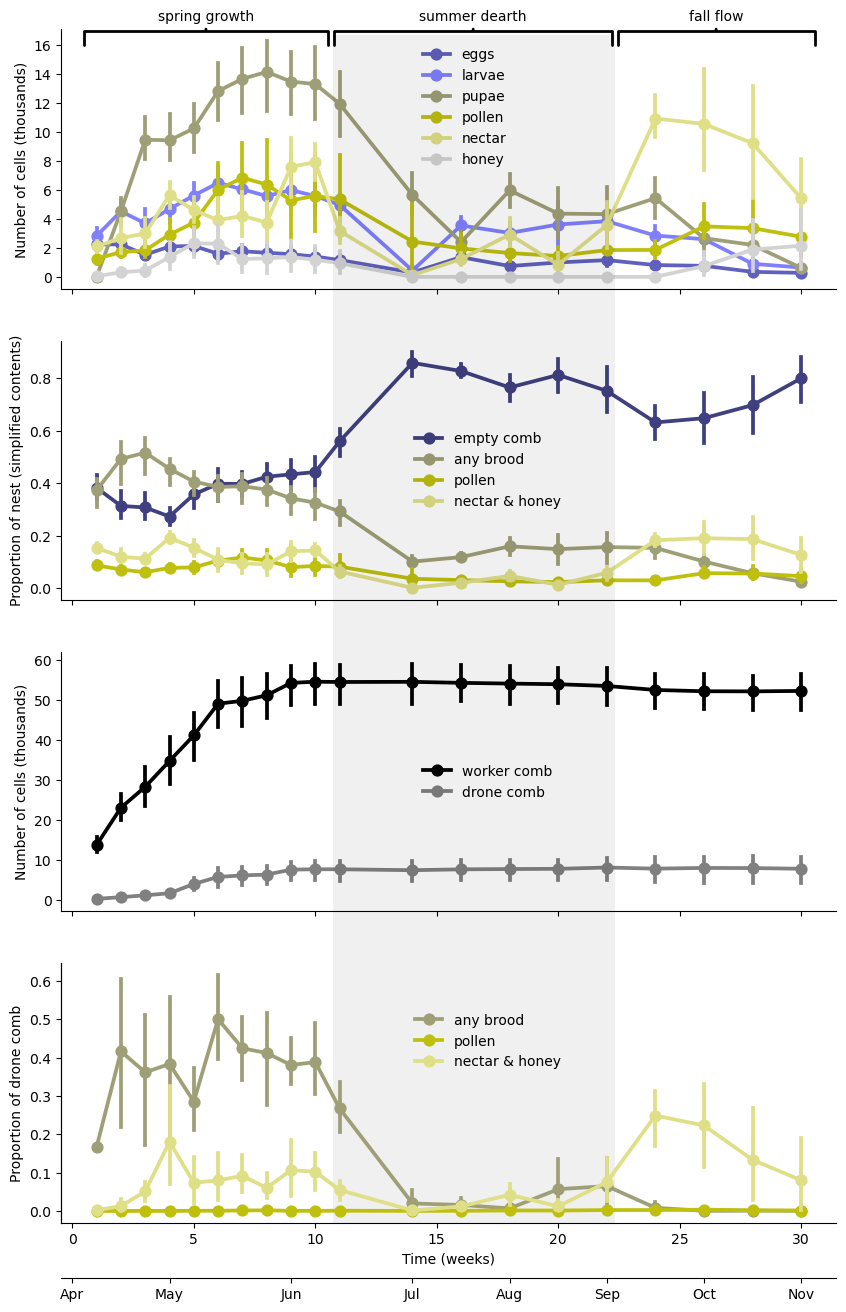

In [10]:
# DDs multiplot composite

fig,ax = plt.subplots(4,1,figsize=(10,15.5), sharex=True)


### CONTENT COUNTS ###

data = df_mergedinsp[(df_mergedinsp['treatment']=='DD')&
                     (~df_mergedinsp.true_week.isin(colony_deadout_week))]
data = data.groupby(by=['colony','true_week']).sum(numeric_only=True).reset_index()
list = ['eggs', 'larvae', 'pupae', 'pollen', 'nectar', 'honey']
for i, content in enumerate(list):
    if i == len(list)-1:
      color = 'lightgrey'
    else:
      color = contenthex[i+3]
    # Use the column values divided by 1000 instead of the string column name
    sns.pointplot(ax=ax[0],
                  data=data,
                  x='true_week',
                  y=data[content]/1000,
                  native_scale=True,
                  label=content,
                  color=color,
                  )
sns.despine()
ax[0].set_ylabel('Number of cells (thousands)')
ax[0].legend(loc='center', bbox_to_anchor=(.52,.7), frameon=False)

# Season labels
labely=17
spring=[1,10]
summer=[10,23]
fall=[23,30]
ax[0].annotate('spring growth', xy=(np.mean(spring),labely),xytext=(np.mean(spring), labely+labely*.03),ha='center', va='bottom',
             arrowprops=dict(arrowstyle='-[, widthB=8.8, lengthB=1', lw=2.0, color='k'))
ax[0].annotate('summer dearth', xy=(np.mean(summer),labely),xytext=(np.mean(summer), labely+labely*.03),ha='center', va='bottom',
             arrowprops=dict(arrowstyle='-[, widthB=10, lengthB=1', lw=2.0, color='k'))
ax[0].annotate('fall flow', xy=(np.mean(fall),labely),xytext=(np.mean(fall), labely+labely*.03),ha='center', va='bottom',
             arrowprops=dict(arrowstyle='-[, widthB=7.1, lengthB=1', lw=2.0, color='k'))


### CONTENT PROPORTIONS ###

data = df_mergedinsp[(df_mergedinsp['treatment']=='DD')&
                     (~df_mergedinsp.true_week.isin(colony_deadout_week))]
data = data.groupby(by=['colony','true_week']).sum(numeric_only=True).reset_index()
data['nectar_honey'] = data['nectar'] +data['honey']
list = ['empty_comb', 'allbrood', 'pollen', 'nectar_honey']
labels = 'empty comb', 'any brood', 'pollen', 'nectar & honey'
for i, content in enumerate(list):
    data['prop'] = data[content]/data['totalcomb']
    if i == 0:
        color = contenthex[2]
    else:
      color = contenthex[i+4]
    sns.pointplot(ax=ax[1],
                  data=data,
              x='true_week',
              y='prop',
              native_scale=True,
              label=labels[i],
              color=color,
              )
ax[1].set_ylabel('Proportion of nest (simplified contents)')
ax[1].legend(loc='center', bbox_to_anchor=(.55,.5), frameon=False)


### DRONE COMB ###

data = df_mergedinsp[(df_mergedinsp['treatment']=='DD')&
                     (~df_mergedinsp.true_week.isin(colony_deadout_week))]
data = data.groupby(by=['colony','true_week']).sum(numeric_only=True).reset_index()
# data['nectar_honey'] = data['nectar'] +data['honey']
list = ['totalworkercomb', 'totaldronecomb',]
colors = ['k', 'grey']
labels = ['worker comb', 'drone comb',]
for i, content in enumerate(list):
    # data['prop'] = data[content]/data['totalcomb']
    sns.pointplot(ax=ax[2],
                  data=data,
              x='true_week',
              y=data[content]/1000,
              native_scale=True,
              label=labels[i],
              color=colors[i],
              )
ax[2].set_ylabel('Number of cells (thousands)')
ax[2].legend(loc='center', bbox_to_anchor=(.55,.5), frameon=False)


### DRONE CONTENT ###

data = df_mergedinsp[(df_mergedinsp['treatment']=='DD')&
                     (~df_mergedinsp.true_week.isin(colony_deadout_week))]
data = data.groupby(by=['colony','true_week']).sum(numeric_only=True).reset_index()
data['drone_nectar_honey'] = data['drone_nectar'] +data['drone_honey']
list = ['drone_allbrood', 'drone_pollen', 'drone_nectar_honey']
labels = ['any brood', 'pollen', 'nectar & honey']
for i, content in enumerate(list):
    data['prop'] = data[content]/data['totaldronecomb']
    color = contenthex[i+5]
    sns.pointplot(ax=ax[3],
                  data=data,
              x='true_week',
              y='prop',
              native_scale=True,
              label=labels[i],
              color=color,
              )
ax[3].set_ylabel('Proportion of drone comb')
ax[3].set_xlabel('Time (weeks)')
ax[3].legend(loc='center', bbox_to_anchor=(.55,.7), frameon=False)

### Add shaded region
import matplotlib.patches as mpatches
rect=mpatches.Rectangle([.397,.11], 0.282, 0.766, 
         ec=None, fc='k', alpha=0.06, clip_on=False, zorder=0,transform=fig.transFigure)
ax[3].add_patch(rect)

# ADD MONTH LABEL
# add column with the month name based on "date_formatted"
df = df_mergedinsp
df['month'] = pd.to_datetime(df['date_formatted']).dt.month_name().str[:3]
df = df.groupby(by=['month']).first().reset_index().sort_values(by='true_week')
df = df[~(df['true_week'].isin(colony_deadout_week))]
df = df[['true_week','month']].reset_index(drop=True)
# manually replace true_week value for Apr to 0
df.loc[df['month']=='Apr', 'true_week'] = 0
# add extra axis at bottom for month labels
ax_month = ax[3].twiny()
ax_month.set_xlim(ax[3].get_xlim())
ax_month.set_xticks(df['true_week'])
ax_month.set_xticklabels(df['month'])
ax_month.xaxis.set_ticks_position('bottom')
ax_month.xaxis.set_label_position('bottom')
ax_month.spines['bottom'].set_position(('outward', 40))
ax_month.set_xlabel('')
sns.despine()


# plt.savefig(userpath + 'Composite_vs_AllWeeks.png', dpi=300, bbox_inches='tight')

# Cell Level

## Neiborhood Composition

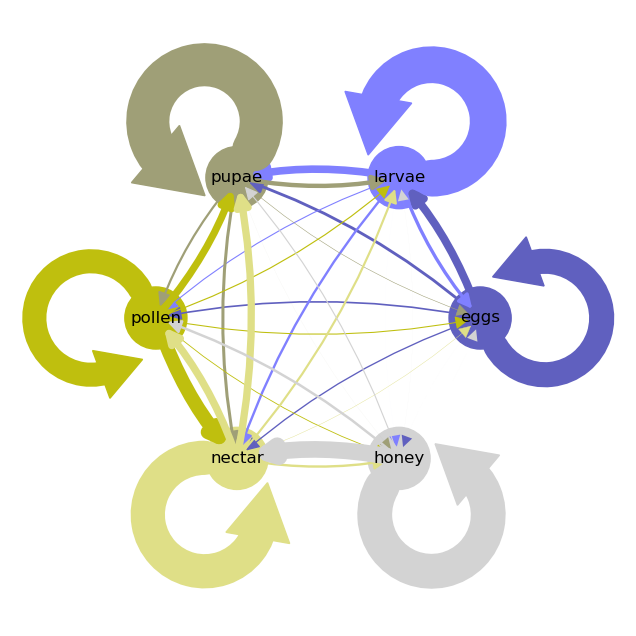

In [39]:
# SELF LOOPS DD colonies first 10 weeks, weights based on abs relationship, not perc diff

data = df_cellneib[(df_cellneib.week<11)
                   &(df_cellneib.treatment=='DD')]
df_cellneib_grouped = data.groupby(by=['focalcontent', 'neibcontent'], as_index=False).mean(numeric_only=True)

# importing networkx
import networkx as nx
import builtins

data = df_cellneib_grouped
data['perc_c'] = 0
data.loc[data.perc_diff>0, 'perc_c'] = 1

# g = nx.Graph()
g = nx.MultiDiGraph()

contentlist =  content_names[3:9]

# make colormap  (content)
colors = contenthex[2:8]
colors.append('lightgrey')

i=0
for content in contentlist:
    df = data[(data['focalcontent']==content)
                    &(data['neibcontent']==content)]
    g.add_node(content, size=2000, node_color=colors[i+1])
    for neib in contentlist:
        if content!=neib:
            df = data[(data['focalcontent']==content)
                        &(data['neibcontent']==neib)]
        
            # g.add_edge(content, neib, weight=abs(df.neibperc)/2, color=colors[df.neibperc])
            g.add_edge(content, neib, weight=abs(df.neibperc)/2, color=colors[i+1])
    i=i+1

c = nx.get_edge_attributes(g,'color').values()
weights = nx.get_edge_attributes(g,'weight').values()

nc = nx.get_node_attributes(g,'node_color').values()
sizes = nx.get_node_attributes(g,'size').values()
 
fig, ax = plt.subplots(figsize=(10,8))
pos = nx.circular_layout(g)
list = builtins.list  # Restore the built-in used by list(...) below

n = nx.draw_networkx_nodes(
    g, pos, ax=ax, node_size=list(sizes), node_color=list(nc)
)
nx.draw_networkx_labels(g, pos, ax=ax)
nx.draw_networkx_edges(g, pos, ax=ax, edge_color=c, width=list(weights), connectionstyle='arc3, rad = 0.1', arrows=True, arrowsize=20, alpha=1)
n.set_zorder(0)
plt.axis('off')
# ax.set_facecolor('k')



# SELF LOOPS #

radius=.7
theta2_= 265
angles = 210 + np.arange(0,len(contentlist))*(360/len(contentlist))

for i in range(len(contentlist)):
    df = data[(data['focalcontent']==contentlist[i])
            &(data['neibcontent']==contentlist[i])]  
    x=pos[contentlist[i]][0]
    y=pos[contentlist[i]][1]
    centX,centY = extrapolate_point(0, 0, x, y, .4)  
    lw = abs(df.neibperc)/2
    color = colors[i+1]
    ax = plt.gca()
    draw_arrow_loop(ax, radius, lw, centX, centY, angles[i], theta2_, color)

# plt.savefig(userpath + 'ContemporaryImmediateCellNeighbors_DD_maxweek10_network_SELF.png', dpi=300, bbox_inches='tight')

## Temporal Transitions

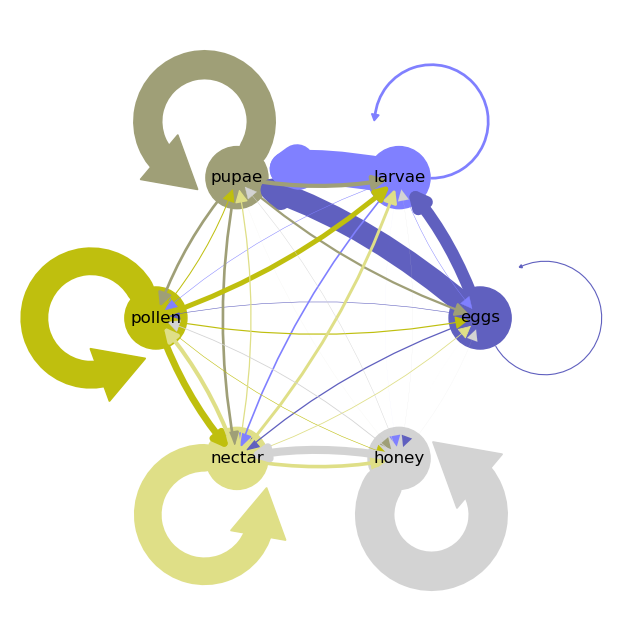

In [40]:
#DD colonies first 10 weeks

data = df_cellfuture[(df_cellfuture.week<11)
                     &(df_cellfuture.treatment=='DD')]
df_cellfuture_grouped = data.groupby(by=['focalcontent', 'nextself'], as_index=False).mean(numeric_only=True)

# importing networkx
import networkx as nx

data = df_cellfuture_grouped

# g = nx.Graph()
g = nx.MultiDiGraph()

contentlist =  content_names[3:9]

# make colormap  (content)
colors = contenthex[2:8]
colors.append('lightgrey')

i=0
for content in contentlist:
    df = data[(data['focalcontent']==content)
                    &(data['nextself']==content)]
    g.add_node(content, size=2000, node_color=colors[i+1])
    for nextself in contentlist:
        if content!=nextself:
            df = data[(data['focalcontent']==content)
                        &(data['nextself']==nextself)]
            g.add_edge(content, nextself, weight=abs(df.nextperc)/3, color=colors[i+1])
    i=i+1

c = nx.get_edge_attributes(g,'color').values()
weights = nx.get_edge_attributes(g,'weight').values()

nc = nx.get_node_attributes(g,'node_color').values()
sizes = nx.get_node_attributes(g,'size').values()
 
fig, ax = plt.subplots(figsize=(10,8))
pos = nx.circular_layout(g)
n = nx.draw_networkx_nodes(g, pos, ax=ax, node_size=list(sizes), node_color=list(nc))
nx.draw_networkx_labels(g, pos, ax=ax)
nx.draw_networkx_edges(g, pos, ax=ax, edge_color=c, width=list(weights), connectionstyle='arc3, rad = 0.1', arrows=True, arrowsize=20, alpha=1)
n.set_zorder(0)
ax.axis('off')  # Hide axes for cleaner look

# SELF LOOPS #

radius=.7
theta2_= 265
angles = 210 + np.arange(0,len(contentlist))*(360/len(contentlist))

for i in range(len(contentlist)):
    df = data[(data['focalcontent']==contentlist[i])
            &(data['nextself']==contentlist[i])]  
    x=pos[contentlist[i]][0]
    y=pos[contentlist[i]][1]
    centX,centY = extrapolate_point(0, 0, x, y, .4)  
    lw = abs(df.nextperc)/2
    color = colors[i+1]
    ax = plt.gca()
    draw_arrow_loop(ax, radius, lw, centX, centY, angles[i], theta2_, color)

# plt.savefig(userpath + 'FutureSelf_DD_maxweek10_network_SELF.png', dpi=300, bbox_inches='tight')

## Cluster Metric

### across comb

In [45]:
# Bootstrapping

data = df_nearestdist[
    (df_nearestdist['treatment']=='DD')
    &(df_nearestdist['week']<11)
    ]
order = [
        'eggs',
        'larvae',
        'pupae',
        'pollen',
        'nectar',
        'honey',
        ]

hierarchy_levels = ['colony']
target = 'dispersion_metric'

boot_sums=[]
for content in order:
    data_sub = data[data['content']==content]
    data_sub = data_sub[hierarchy_levels + [target]]
    bootstrap_res = hierarchical_bootstrap(data_sub, hierarchy_levels, n_bootstraps=4000)
    summary = bootstrap_summary_stats(bootstrap_res[target].values)
    boot_sums.append(summary)
    print(content + ': ' + str(summary['median']) + ' (' + str(summary['lower_bounds']) + ' - ' + str(summary['upper_bounds']) + ')')

# ~ 6min lab comp

Bootstrapping: 100%|██████████| 4000/4000 [00:04<00:00, 884.10it/s] 


eggs: 0.8210864756755701 (0.7726382370860775 - 0.8496694564054206)


Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 2845.91it/s]


larvae: 0.8262208265765383 (0.7868817700590836 - 0.8526698739125955)


Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 3914.99it/s]


pupae: 0.8152309357334342 (0.7877717009351323 - 0.8367452008764114)


... (2 outputs left out)

Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 3655.82it/s]


nectar: 0.7145717814625352 (0.6966653394215035 - 0.7337044027966659)


Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 2632.07it/s]


honey: 0.9592814912102474 (0.9509826519357807 - 0.9680009205421038)


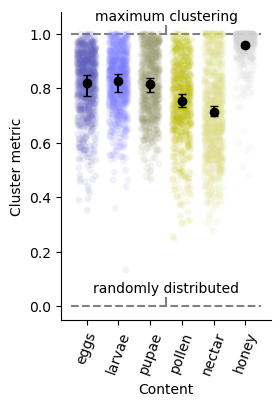

In [46]:
# Show actual datapoints with the boostrapped mean and 95%CI

data = df_nearestdist[
    (df_nearestdist['treatment']=='DD')
    &(df_nearestdist['week']<11)
    ]
order = [
        'eggs',
        'larvae',
        'pupae',
        'pollen',
        'nectar',
        'honey',
        ]
colors = contenthex[3:8]
colors.append('lightgrey')

plt.figure(figsize=(2.7,4))
ax=sns.stripplot(data=data, 
                y='dispersion_metric',
                x='content',
                palette=colors,
                jitter=.3,
                alpha=.1,
                order=order,
                )

medians = [sublist['median'] for sublist in boot_sums]
errors = [sublist['errors'] for sublist in boot_sums]
ax=plt.errorbar(x=np.arange(len(order)),
             y=medians,
             yerr=np.array(errors).T,
             fmt='o',
             capsize=3,
            #  elinewidth=2,
            #  markeredgewidth=2,
            #  markersize=8,
             color='k',
             zorder=10000)

plt.xlabel('Content')
plt.ylabel('Cluster metric')
plt.xticks(order, rotation=70)
plt.plot([-.5,5.5],[1,1], c='grey',ls='--')
plt.plot([-.5,5.5],[0,0], c='grey',ls='--')
plt.text(2.5,1.05,'maximum clustering', horizontalalignment='center')
plt.text(2.5,.05,'randomly distributed', horizontalalignment='center')
plt.plot([2.5,2.5],[.03,0], c='grey',)
plt.plot([2.5,2.5],[1.03,1], c='grey',)
sns.despine()

# plt.savefig(userpath + 'CombLevel_DispersionMetric_Contents_Bootstrapped.png', dpi=300, bbox_inches='tight')

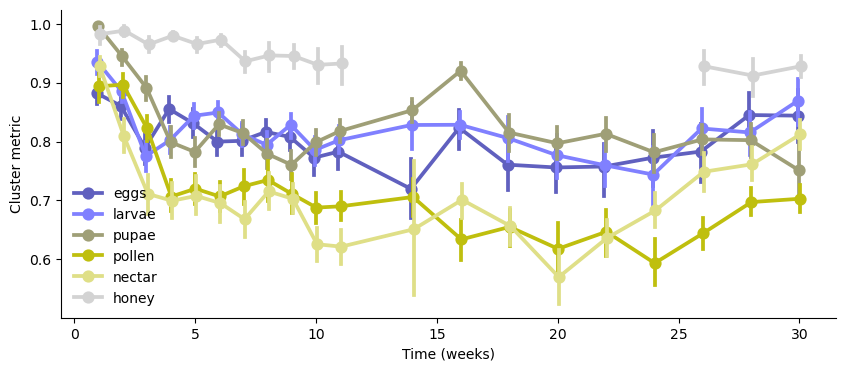

In [47]:
data = df_nearestdist[
    (df_nearestdist['treatment']=='DD')
    &(~df_nearestdist['true_week'].isin(colony_deadout_week))
    # &(df_nearestdist['week']<11)
    ]
colors = contenthex[3:8]
colors.append('lightgrey')
order = [
        'eggs',
        'larvae',
        'pupae',
        'pollen',
        'nectar',
        'honey',
        ]
plt.figure(figsize=(10,4))

sns.pointplot(data=data,
            x='true_week',
            y='dispersion_metric',
            hue='content',
            palette = colors,
            dodge=True,
            hue_order=order,
            native_scale=True,
            )
# plt.ylim(0,1)
sns.despine()
plt.xlabel('Time (weeks)')
plt.ylabel('Cluster metric')
plt.legend(frameon=False)

# plt.savefig(userpath + 'CombLevel_DispersionMetric_AllTime_byContent_sm.png', dpi=300, bbox_inches='tight')

### across nest

In [48]:
data = df_nearestdist_nest[
    (df_nearestdist_nest['treatment']=='DD')
    &(df_nearestdist_nest['week']<11)
    ]
order = [
        'eggs',
        'larvae',
        'pupae',
        'pollen',
        'nectar',
        'honey',
        ]

hierarchy_levels = ['colony']
target = 'dispersion_metric'

boot_sums=[]
for content in order:
    data_sub = data[data['content']==content]
    data_sub = data_sub[hierarchy_levels + [target]]
    bootstrap_res = hierarchical_bootstrap(data_sub, hierarchy_levels, n_bootstraps=4000)
    summary = bootstrap_summary_stats(bootstrap_res[target].values)
    boot_sums.append(summary)
    print(content + ': ' + str(summary['median']) + ' (' + str(summary['lower_bounds']) + ' - ' + str(summary['upper_bounds']) + ')')

# ~ 6min lab comp

Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 3965.85it/s]


eggs: 0.8424960422545869 (0.7886830391088485 - 0.8785632574776432)


Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 3124.69it/s]


larvae: 0.8707844820509377 (0.8311893642590479 - 0.8941578023916801)


Bootstrapping: 100%|██████████| 4000/4000 [00:00<00:00, 4117.27it/s]


pupae: 0.8765377120497843 (0.8492648055843274 - 0.8951858411805963)


... (2 outputs left out)

Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 3869.64it/s]


nectar: 0.7197708017192613 (0.6893285117770006 - 0.7544143951692999)


Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 3898.63it/s]


honey: 0.9799684007940475 (0.9691512499247824 - 0.9852744266694421)


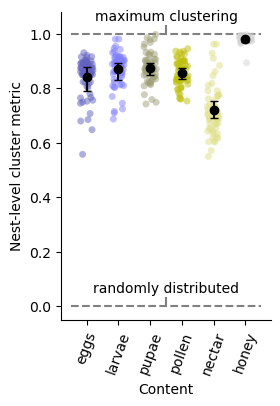

In [49]:
# Show actual datapoints with the boostrapped mean and 95%CI

data = df_nearestdist_nest[
    (df_nearestdist_nest['treatment']=='DD')
    &(df_nearestdist_nest['week']<11)
    ]
order = [
        'eggs',
        'larvae',
        'pupae',
        'pollen',
        'nectar',
        'honey',
        ]
colors = contenthex[3:8]
colors.append('lightgrey')

plt.figure(figsize=(2.7,4))
ax=sns.stripplot(data=data, 
                y='dispersion_metric',
                x='content',
                palette=colors,
                jitter=.2,
                alpha=.5,
                order=order,
                )

medians = [sublist['median'] for sublist in boot_sums]
errors = [sublist['errors'] for sublist in boot_sums]
ax=plt.errorbar(x=np.arange(len(order)),
             y=medians,
             yerr=np.array(errors).T,
             fmt='o',
             capsize=3,
            #  elinewidth=2,
            #  markeredgewidth=2,
            #  markersize=8,
             color='k',
             zorder=10000)

plt.xlabel('Content')
plt.ylabel('Nest-level cluster metric')
plt.xticks(order, rotation=70)
plt.plot([-.5,5.5],[1,1], c='grey',ls='--')
plt.plot([-.5,5.5],[0,0], c='grey',ls='--')
plt.text(2.5,1.05,'maximum clustering', horizontalalignment='center')
plt.text(2.5,.05,'randomly distributed', horizontalalignment='center')
plt.plot([2.5,2.5],[.03,0], c='grey',)
plt.plot([2.5,2.5],[1.03,1], c='grey',)
sns.despine()

# plt.savefig(userpath + 'NestLevel_DispersionMetric_Contents_Nest_Bootstrapped.png', dpi=300, bbox_inches='tight')

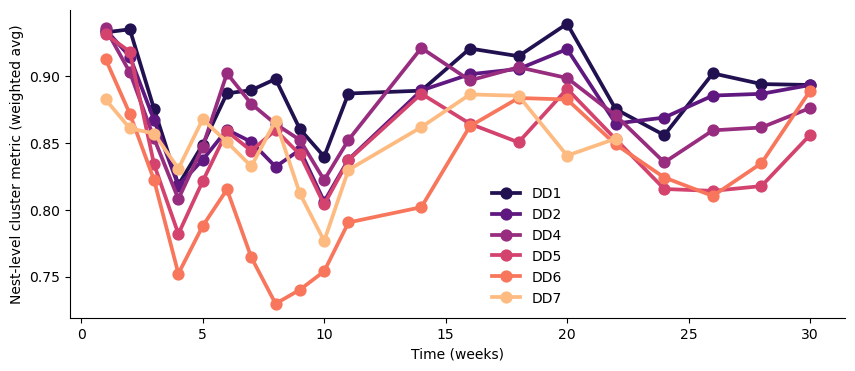

In [50]:
# weighted avg
# by colony
# all weeks

data = df_nearestdist_nest_sum[
    (df_nearestdist_nest_sum['treatment']=='DD')
    &(~df_nearestdist_nest_sum['true_week'].isin(colony_deadout_week))
    # &(df_nearestdist_nest_sum['week']<11)
    ]

plt.figure(figsize=(10,4))
sns.pointplot(data=data,
            x='true_week',
            y='dispersion_metric',
            hue='colony',
            palette='magma',
            native_scale=True,
            )
# plt.ylim(0,1)
sns.despine()
plt.xlabel('Time (weeks)')
plt.ylabel('Nest-level cluster metric (weighted avg)')
plt.legend(frameon=False, loc='lower right', bbox_to_anchor=(.65,0))

plt.savefig(userpath + 'NestLevel_ClusterMetric_ALLTime_weightedavg_colony_sm.png', dpi=300, bbox_inches='tight')

# Comb Level

## Comb PCA

In [17]:
# Select variables for analysis

variables = [
#  'empty_comb',                  # makeup
#  'eggs',                        # makeup
#  'larvae',                      # makeup
#  'pupae',                       # makeup                   
#  'pollen',                      # makeup
#  'nectar',                      # makeup
#  'honey',                       # makeup
#  'nectar_honey',                # makeup
 'totalcomb',                   # size/shape
 'perc_empty_comb',             # makeup
#  'perc_eggs',                   # makeup
#  'perc_larvae',                 # makeup
#  'perc_pupae',                  # makeup
 'perc_pollen',                 # makeup
#  'perc_nectar',                 # makeup
#  'perc_honey',                  # makeup
 'perc_nectar_honey',           # makeup
 'perc_allbrood',               # makeup
#   'worker_allbrood',            # makeup
#  'drone_allbrood',              # makeup
#  'allbrood',                    # makeup
#  'perc_totaldronecomb',         # makeup  
#   'comb_height',                # size/shape
#   'comb_width',                 # size/shape
 'comb_aspecthw',               # size/shape
#  'comb_perim',                  # size/shape
 'comb_perim_area_ratio',       # size/shape
#  'bees_onframe',
#  'n_comb_neibs',
#   'framesfromfirst',
#   'number_of_patches',          # landscape
#  'patch_density',               # landscape
#  'largest_patch_index',         # landscape
#  'total_edge',                  # landscape
#  'edge_density',                # landscape
 'landscape_shape_index',       # landscape        content egdeyness, shape complexity
#  'effective_mesh_size',         # landscape
#  'entropy',                     # landscape
 'shannon_diversity_index',     # landscape           diversity
#  'joint_entropy',               # landscape
#  'conditional_entropy',         # landscape           lanscape shape complexity
#  'mutual_information',          # landscape
#  'relative_mutual_information', # landscape
#  'contagion',                   # landscape
#  'area_mn',                     # size/shape
#  'perimeter_mn',                # size/shape
#  'perimeter_area_ratio_mn',     # size/shape
#  'shape_index_mn',              # size/shape
#  'fractal_dimension_mn',        # landscape
#  'euclidean_nearest_neighbor_mn', # landscape
 'dispersion_metric'            # landscape           clustering/dispersal
]

# 4 makeup
# 3 size/shape
# 3 landscape

Text(0.5, 0, 'Components')

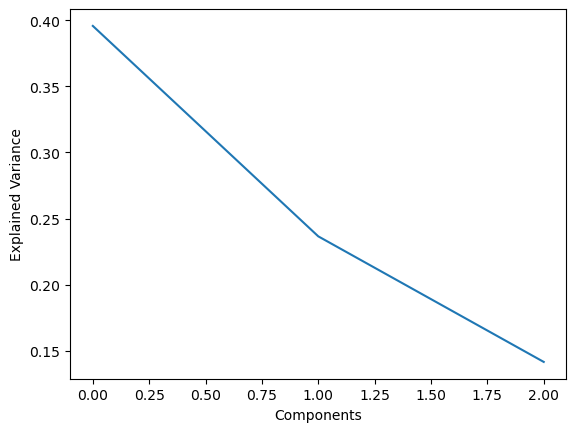

In [18]:
from sklearn import decomposition
from sklearn import datasets
from sklearn.preprocessing import scale

n_components = 3

# load dataset
data = df_mergedinsp[(df_mergedinsp['treatment']=='DD')
                     &(~df_mergedinsp.true_week.isin(colony_deadout_week))
                     &(df_mergedinsp['comb_perim_area_ratio']!=np.inf)
                    #  &(df_mergedinsp['side']=='a')
                     ]

data = data[variables]

# log transform data (natural log + 1)
df_logtrans = np.log1p(data)

# normalize data (z-score)
df_normalized=(df_logtrans - df_logtrans.mean()) / df_logtrans.std()

df_head = df_mergedinsp[df_mergedinsp.columns.tolist()[:6]]
df_combined = pd.concat([df_head, df_normalized], axis=1)

df_normalized = df_normalized.dropna().reset_index(drop=True)
df_combined = df_combined.dropna().reset_index(drop=True)

# apply PCA
pca = decomposition.PCA(n_components=n_components)
PCAvalues = pca.fit_transform(df_normalized)

# Reformat and view results
loadings = pd.DataFrame(pca.components_.T,
                        columns=['PC%s' % _ for _ in range(n_components)],
                        index=data.columns)

plt.plot(pca.explained_variance_ratio_)
plt.ylabel('Explained Variance')
plt.xlabel('Components')

In [19]:
pca.explained_variance_ratio_

array([0.3958369 , 0.23650377, 0.14141857])

In [20]:
loadings.loc[(loadings.PC0 > -.2)&(loadings.PC0 < .2), 'PC0'] = 0

loadingPC0 = loadings.loc[loadings.PC0!=0]

loadingPC0.sort_values(by=['PC0'], ascending=False)

,PC0,PC1,PC2
shannon_diversity_index,0.515570,0.096296,0.002761
perc_allbrood,0.446868,0.195749,-0.532781
landscape_shape_index,0.388450,-0.165977,-0.173517
perc_nectar_honey,0.279879,0.173339,0.589405
perc_pollen,0.236059,-0.528884,0.476972
perc_empty_comb,-0.495433,-0.080763,-0.070200


In [21]:
loadings.loc[(loadings.PC1 > -.2)&(loadings.PC1 < .2), 'PC1'] = 0

loadingPC1 = loadings.loc[loadings.PC1!=0]

loadingPC1.sort_values(by=['PC1'], ascending=False)

,PC0,PC1,PC2
dispersion_metric,0.000000,0.737616,0.219916
comb_aspecthw,0.000000,0.215931,0.222418
perc_pollen,0.236059,-0.528884,0.476972


In [22]:
df_PCAvalues = pd.DataFrame({'PC0':PCAvalues[:,0],
                        'PC1':PCAvalues[:,1],
                        'PC2':PCAvalues[:,2],})
df_PCAvalues

,PC0,PC1,PC2
0,-0.921109,1.883017,0.580419
1,-0.905017,1.817807,0.765346
2,0.881693,1.733749,1.144008
3,0.762018,1.413388,1.011950
4,1.328189,1.653722,1.075062
...,...,...,...
1874,-1.263779,-0.782915,-0.807634
1875,-1.714863,-0.899387,-0.644952
1876,-2.270101,-0.995290,0.755105
1877,-3.944837,0.149864,-0.412131


In [23]:
df_head = df_combined[df_combined.columns.tolist()[:6]]
df_PCA = pd.concat([df_head, df_PCAvalues], axis=1)
df_PCA['frame_reoriented'] = df_PCA.frame
df_PCA.loc[(df_PCA.colony!='DD6')|(df_PCA.colony!='DD7')|(df_PCA.colony!='SH4'), 'frame_reoriented'] = 11 - df_PCA.frame

# remove one weird frame that is way off on its own (high percent pollen and very dispersed)
df_PCA = df_PCA[~((df_PCA['colony']=='DD1')&(df_PCA['true_week']==16)&(df_PCA['frame']==9)&(df_PCA['side']=='b'))]

df_PCA

,colony,date,week,true_week,frame,side,PC0,PC1,PC2,frame_reoriented
0,DD1,20210412,1,1,5,a,-0.921109,1.883017,0.580419,6
1,DD1,20210412,1,1,5,b,-0.905017,1.817807,0.765346,6
2,DD1,20210412,1,1,6,a,0.881693,1.733749,1.144008,5
3,DD1,20210412,1,1,6,b,0.762018,1.413388,1.011950,5
4,DD1,20210412,1,1,7,a,1.328189,1.653722,1.075062,4
...,...,...,...,...,...,...,...,...,...,...
1874,DD7,20210910,16,22,4,a,-1.263779,-0.782915,-0.807634,7
1875,DD7,20210910,16,22,4,b,-1.714863,-0.899387,-0.644952,7
1876,DD7,20210910,16,22,5,a,-2.270101,-0.995290,0.755105,6
1877,DD7,20210910,16,22,5,b,-3.944837,0.149864,-0.412131,6


[Text(-0.4, 0, '-0.4'), Text(0.0, 0, '0'), Text(0.4, 0, '0.4')]

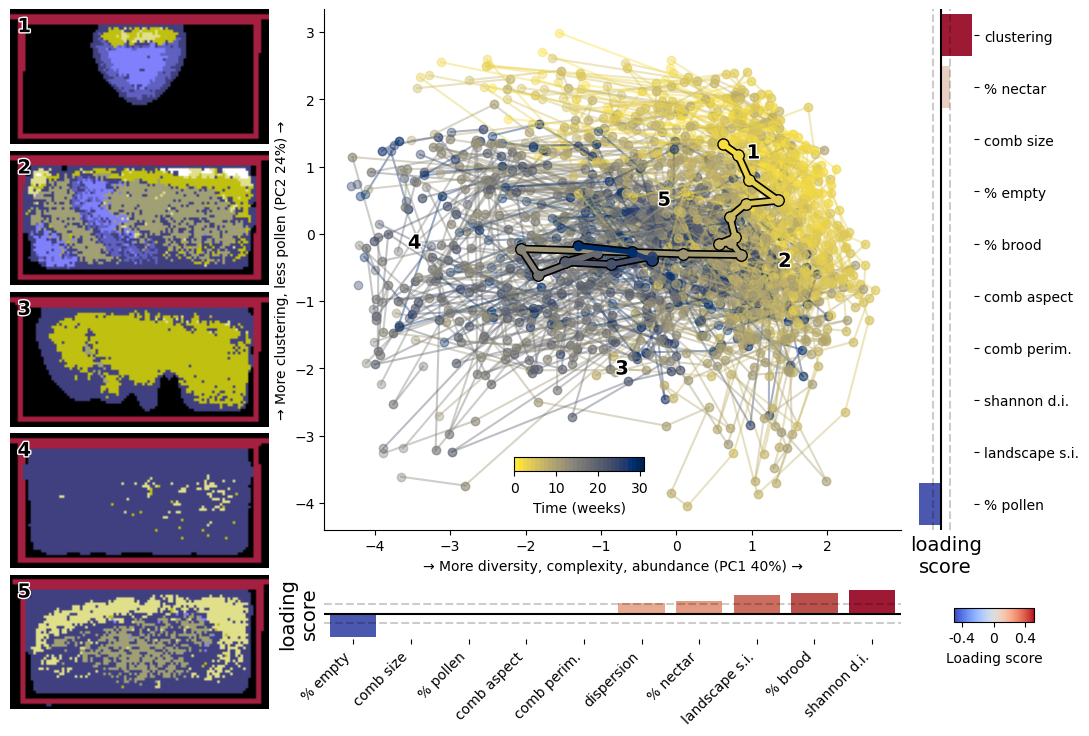

In [24]:
# Label updates
# ADD 5 MASKS AROUND SELECTED
# lines by frame
# AGAIN, JUST DDs
# invert axes
# Colored mean line
# SMALLER
# WITH LOADINGS

data = df_PCA

colormap = 'cividis_r'
Nmax = np.max(data.true_week)+1
Nmin = np.min(data.true_week)-1
Nlen = int(Nmax - Nmin)
cmap = matplotlib.cm.get_cmap(colormap, Nlen)
colors = cmap(np.linspace(0, 1, Nlen))

fig = plt.figure(figsize=(10,7), constrained_layout=False)


# PCA POINTS #

gs1 = GridSpec(2, 2, left=.35, right=1, top=1, bottom=.1, figure=fig, wspace=.05, hspace=.2, width_ratios=[1, .1], height_ratios=[1, .1])
ax1 = fig.add_subplot(gs1[0,0])
for c in range(6):
    for f in range(20):
        for side in ['a','b']:
            df = data[(data['colony']==colony_names[c])
                  &(data['frame']==f+1)
                  &(data['side']==side)
                 ]
            for w in df.week.unique().tolist()[1:]:
                df2 = df[(df['week']==w-1)
                        |(df['week']==w)
                        ]
                ax = ax1.plot(df2.PC0,df2.PC1,marker='o',color=colors[int(df2.true_week.unique().tolist()[0])], alpha=.4)

df = data[['week','true_week', 'PC0', 'PC1']].groupby(by=['week', 'true_week']).mean().reset_index()
for i in df.week.unique().tolist()[1:]:
    df2 = df[(df.week==i-1)|(df.week==i)]
    ax1.plot(df2.PC0,df2.PC1,marker='o', ms=8, lw=6, color='k', zorder=10000)
    ax1.plot(df2.PC0,df2.PC1,marker='o', ms=6, lw=3.5, color=colors[int(df2.true_week.unique().tolist()[0])], zorder=10001)
ax1.set_xlabel('→ More diversity, complexity, abundance (PC1 ' + str(round(pca.explained_variance_ratio_[0]*100)) + '%) →')
ax1.set_ylabel('→ More clustering, less pollen (PC2 ' + str(round(pca.explained_variance_ratio_[1]*100)) + '%) →')
sns.despine()

# colorbar
norm = mpl.colors.Normalize(vmin=Nmin, vmax=Nmax)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
ticks = np.arange(round(Nmin,-2), Nmax, round(Nlen/4,-1))
cbar_ax = fig.add_axes([.54, .34, .13, .02])
cbar = plt.colorbar(sm, ticks=ticks, shrink=.4, orientation='horizontal', cax=cbar_ax)
cbar.set_label("Time (weeks)")


# EXAMPLE FRAMES #

gs2 = GridSpec(5, 1, left=0, right=.33, top=1, bottom=0, figure=fig, hspace=.05)
sides = ['a','b']

# intentionally select
cs = [4,  1,  0,  0,  0]
ws = [1,  8,  6, 12, 16]
fs = [1,  6,  9,  2,  5]
ss = [0,  1,  0,  1,  1]

for i in range(5):
    ax = fig.add_subplot(gs2[i])

    # for intentionally selected masks
    df = data[(data['colony']==colony_names[cs[i]])
              &(data['week']==ws[i]+1)
              &(data['frame']==fs[i]+1)
              &(data['side']==sides[ss[i]])
              ]
    mask = Contents[cs[i]][ws[i]][fs[i]*2 + ss[i]]
    mask = np.where(mask>8,2,mask)  # cap at 8 for visualization (turns qcup, bees into empty comb)
    ax1.text(float(df.PC0), float(df.PC1), s=str(i+1), c='k', ha='center', va='center', weight='bold', fontsize=14, path_effects=[pe.withStroke(linewidth=2, foreground="w")], zorder=10002)

    ax.imshow(mask, cmap='gist_stern', vmin=0, vmax=8)
    ax.axis('off')
    ax.text(mask.shape[1]*.05,mask.shape[0]*.12,str(i+1),c='k', ha='center', va='center', weight='bold', fontsize=14, path_effects=[pe.withStroke(linewidth=2, foreground="w")])



# PC LOADINGS #
# PC1
ax = fig.add_subplot(gs1[1,0])
sns.barplot(ax=ax,
            data=loadings,
            y='PC0',
            x=loadings.index,
            hue='PC0',
            palette='coolwarm',
            orient='v',
            order=loadings.sort_values(by=['PC0'], ascending=True).index.tolist(),
            )
ax.legend([],[], frameon=False)
ax.set_ylabel('loading\nscore', fontsize=14)
ax.set_xlabel('')
ax.axhline(-.2, color='k', linestyle='--', alpha=.2)
ax.axhline(0, color='k')
ax.axhline(.2, color='k', linestyle='--', alpha=.2)
labels = ['% empty', 'comb size', '% pollen', 'comb aspect', 'comb perim.', 'dispersion', '% nectar', 'landscape s.i.', '% brood', "shannon d.i."]
ax.set_yticks([])
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# PC2
ax = fig.add_subplot(gs1[0,1])
lodings = loadings.sort_values(by=['PC1'], ascending=False)
sns.barplot(ax=ax,
            data=loadings,
            x='PC1',
            y=loadings.index,
            hue='PC1',
            palette='coolwarm',
            orient='h',
            order=loadings.sort_values(by=['PC1'], ascending=False).index.tolist(),
            )
ax.legend([],[], frameon=False)
ax.set_xlabel('loading\nscore', fontsize=14)
ax.set_ylabel('')
ax.axvline(-.2, color='k', linestyle='--', alpha=.2)
ax.axvline(0, color='k')
ax.axvline(.2, color='k', linestyle='--', alpha=.2)
labels = ['clustering', '% nectar', 'comb size', '% empty', '% brood', 'comb aspect', 'comb perim.', "shannon d.i.",  'landscape s.i.', '% pollen']
ax.set_xticks([])
ax.yaxis.tick_right()
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels)
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# LOADING colorbar
colormap = 'coolwarm'
Nmax = np.max(loadings.PC0)
Nmin = np.min(loadings.PC0)
Nlen = 100
cmap = matplotlib.cm.get_cmap(colormap, Nlen)
colors = cmap(np.linspace(0, 1, Nlen))

norm = mpl.colors.Normalize(vmin=Nmin, vmax=Nmax)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
ticks = [-.4, 0, .4]
ticklabels = ['-0.4', '0', '0.4']
cbar_ax = fig.add_axes([.98, .125, .08, .02])
cbar = plt.colorbar(sm, ticks=ticks, shrink=.4, orientation='horizontal', cax=cbar_ax,)
cbar.set_label("Loading score")
cbar.ax.set_xticklabels(ticklabels)

# plt.savefig(userpath + 'CombPCA_reduced_DD_AllWeeks_coloredmean_5MASKS_selected_altcolor_loadings.png', dpi=300, bbox_inches='tight', pad_inches=0)


## Vertical Distribution

In [60]:
maxweek=10

appended=[]
for c in range(12):
    for w in range(maxweek):
        df_temp = xyz_coords(Contents[c][w], content_names[2:9], contents=np.arange(2,9))
        appended.append(df_temp)

df_coords = pd.concat(appended).reset_index(drop=True)
df_coords['week'] = df_coords['week'] + 1
df_coords['treatment'] = df_coords['colony'].astype(str).str[:2]

# Calculate comb size
df_coords['totalcomb'] = df_coords.groupby(['colony','week','z'])['content'].transform('count')

# Simplify comb contents
df_coords['content_simple'] = df_coords['content']
df_coords.loc[(df_coords.content == 'eggs')|(df_coords.content == 'larvae')|(df_coords.content == 'pupae'), 'content_simple'] = 'any_brood'
df_coords.loc[(df_coords.content == 'honey')|(df_coords.content == 'nectar'), 'content_simple'] = 'nectar_honey'

# Find comb height
df_coords['comb_ymin'] = df_coords.groupby(['colony','week','z'])['y'].transform('min')
df_coords['comb_ymax'] = df_coords.groupby(['colony','week','z'])['y'].transform('max')
df_coords['comb_height'] = df_coords['comb_ymax'] - df_coords['comb_ymin']
df_coords['y_prop'] = ((df_coords['y'] - df_coords['comb_ymin']) / df_coords['comb_height'])*100

# Find comb width
df_coords['comb_xmin'] = df_coords.groupby(['colony','week','z'])['x'].transform('min')
df_coords['comb_xmax'] = df_coords.groupby(['colony','week','z'])['x'].transform('max')
df_coords['comb_width'] = df_coords['comb_xmax'] - df_coords['comb_xmin']
df_coords['x_prop'] = ((df_coords['x'] - df_coords['comb_xmin']) / df_coords['comb_width'])*100

# Reorder frames (z) so low values are closer to nest initiation point
df_coords['z_RO'] = 19 - df_coords['z']
df_coords.loc[df_coords['colony'].isin(['DD6','DD7','SH4']), 'z_RO'] = df_coords['z']

# Reorder x values so low values are closer to where the comb was initiated 
df_coords['x_RO'] = df_coords['x']
df_coords['comb_xmin_RO'] = df_coords['comb_xmin']
df_coords.loc[(df_coords['comb_ymax'] == df_coords['y']), 'y_max_match'] = 1
df_coords.loc[(df_coords['y_max_match'] == 1) & (df_coords['x']> Contents[0][0][0].shape[1]/2), 'x_flip'] = 1
df_coords['x_flip'] = df_coords.groupby(['colony','week','z'])['x_flip'].transform('max')
df_coords.loc[(df_coords['x_flip'] == 1), 'x_RO'] = Contents[0][0][0].shape[1] - df_coords['x']
df_coords.loc[(df_coords['x_flip'] == 1), 'comb_xmin_RO'] = Contents[0][0][0].shape[1] - df_coords['comb_xmin'] - df_coords['comb_width']
df_coords['x_RO_prop'] = ((df_coords['x_RO'] - df_coords['comb_xmin_RO']) / df_coords['comb_width'])*100

df_coords

# ~ 1min

,z,y,x,zspaced,contentid,content,colony,week,treatment,totalcomb,content_simple,comb_ymin,comb_ymax,comb_height,y_prop,comb_xmin,comb_xmax,comb_width,x_prop,z_RO,x_RO,comb_xmin_RO,y_max_match,x_flip,x_RO_prop
0,8,6,68,20,2.0,empty_comb,DD1,1.0,DD,693,empty_comb,6,37,31,0.000000,66,93,27,7.407407,11,32,7,NaN,1.0,92.592593
1,8,6,69,20,2.0,empty_comb,DD1,1.0,DD,693,empty_comb,6,37,31,0.000000,66,93,27,11.111111,11,31,7,NaN,1.0,88.888889
2,8,6,70,20,2.0,empty_comb,DD1,1.0,DD,693,empty_comb,6,37,31,0.000000,66,93,27,14.814815,11,30,7,NaN,1.0,85.185185
3,8,6,71,20,2.0,empty_comb,DD1,1.0,DD,693,empty_comb,6,37,31,0.000000,66,93,27,18.518519,11,29,7,NaN,1.0,81.481481
4,8,6,72,20,2.0,empty_comb,DD1,1.0,DD,693,empty_comb,6,37,31,0.000000,66,93,27,22.222222,11,28,7,NaN,1.0,77.777778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5498702,19,12,77,46,8.0,honey,SH7,10.0,SH,3380,nectar_honey,6,45,39,15.384615,5,93,88,81.818182,0,23,7,NaN,1.0,18.181818
5498703,19,12,79,46,8.0,honey,SH7,10.0,SH,3380,nectar_honey,6,45,39,15.384615,5,93,88,84.090909,0,21,7,NaN,1.0,15.909091
5498704,19,13,7,46,8.0,honey,SH7,10.0,SH,3380,nectar_honey,6,45,39,17.948718,5,93,88,2.272727,0,93,7,NaN,1.0,97.727273
5498705,19,13,9,46,8.0,honey,SH7,10.0,SH,3380,nectar_honey,6,45,39,17.948718,5,93,88,4.545455,0,91,7,NaN,1.0,95.454545


Text(0.5, 0.03, 'Comb size (fraction of full comb)')

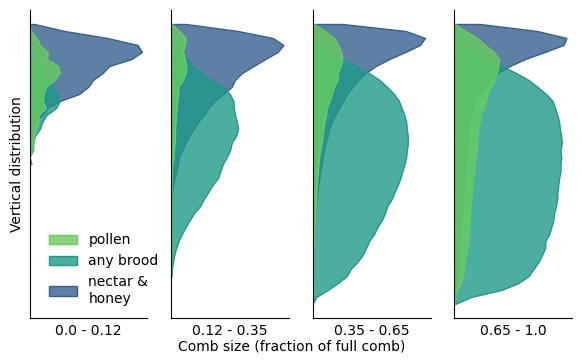

In [61]:
# LOG SPACED BINS
# fewer bins
# NOT SMOOTH

content_simple = ['any_brood', 'pollen', 'nectar_honey']
hex = [simplehex[1], simplehex[0], simplehex[2]]
nbins = 4
maxsize = np.size(ContentsCrop[0][0][0])
bins = powspace(start=0, stop=maxsize, power=1.5, num=nbins+1) # log spaced bins

fig,ax = plt.subplots(1,nbins,figsize=(7,4), sharey=True)
ax[0].invert_yaxis()
for i in range(nbins):
    lo = bins[i]
    hi = bins[i+1]-1
    data = df_coords[(df_coords['treatment']=='DD')&
                     (df_coords['totalcomb']>lo)&
                     (df_coords['totalcomb']<hi)&
                     (df_coords['content_simple'].isin(content_simple))]
    data = pd.concat([data[data['content_simple'] == 'pollen'], data[data['content_simple'] != 'pollen']]) # sort so pollen is in forground
    sns.histplot(ax=ax[i],
                  data=data,
                  y='y',
                  hue='content_simple',
                  fill=True,
                  alpha=.8,
                  palette=hex,
                  element='poly',
                  binwidth=1,
                  )
    ax[i].set_xticks([])
    ax[i].set_xlabel(str(round(lo/maxsize,2)) + ' - ' + str(round(hi/maxsize,2)))
    ax[i].set_yticks([])
    sns.despine()
    if i==0:
        ax[i].set_ylabel('Vertical distribution')
        sns.move_legend(ax[i], "lower right", title='', labels=['pollen', 'any brood', 'nectar &\nhoney'], frameon=False, bbox_to_anchor=(1.2, 0), fontsize=10)
    # elif i==nbins-1:
    #     sns.move_legend(ax[i], "upper right", frameon=False, bbox_to_anchor=(2.7, 1))
    else:
        ax[i].set_ylabel('')
        ax[i].legend([],[], frameon=False)

fig.text(0.5, 0.03, 'Comb size (fraction of full comb)', ha='center')
# plt.savefig(userpath + 'SimpleContentDistribution_maxweek'+ str(maxweek) + '_CombSize' + str(nbins) + 'POWERbins_notsmooth.png', dpi=300, bbox_inches='tight')
# ~ 16s

# Nest Level

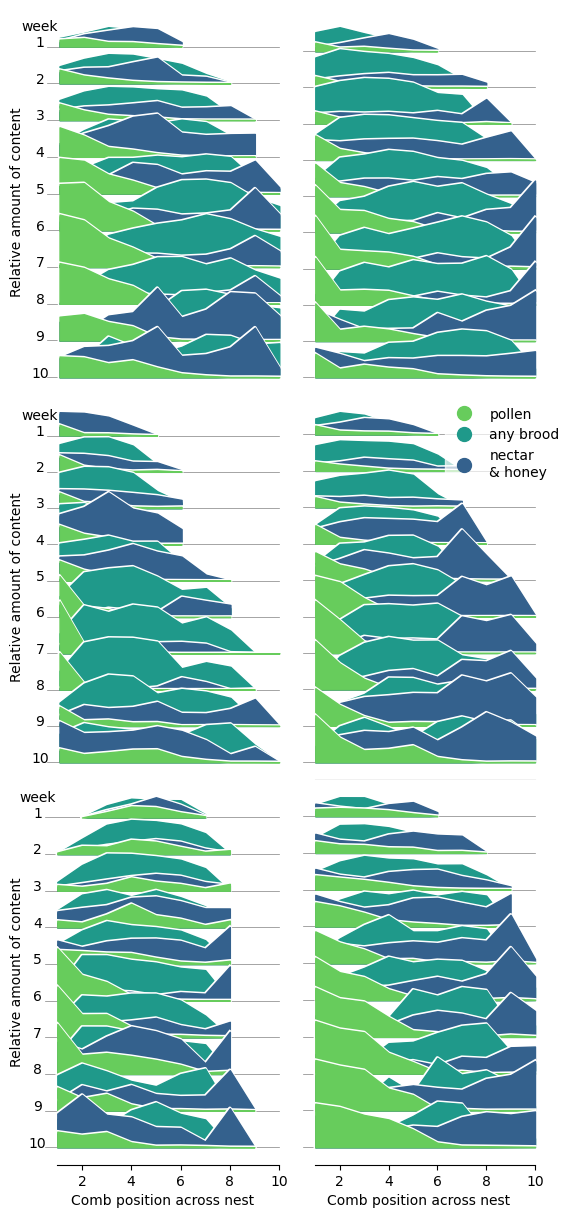

In [ ]:
# NECTAR POLLEN BROOD DISTRIBUTION
# all DDs composite fig (separated by colony) SMALL
# 3 rows 2 cols
#all DD colonies
# NOT smoothed

# Simplified contents

# data
smoothnum = 200
yoffset=.7
lw=2.5
maxweek=11
alpha=1

fig,ax = plt.subplots(3,2, figsize=(6.6,15))
ax = ax.reshape(-1)

for c in range(6):
    data = df_mergedinsp[(df_mergedinsp['colony']==colony_names[c])&
                        (df_mergedinsp['week']<maxweek+1)
                        ].reset_index(drop=True)
    data = data[['colony',
                        'week',
                        'frame',
                        'pollen',
                        'nectar_honey',
                        'allbrood',
                        'totalcomb'
                        ]]
    data = data.groupby(['colony','week','frame'], as_index=False).mean()

    maxpupae = np.max(data.allbrood)
    maxpollen = np.max(data.pollen)
    maxnectar = np.max(data.nectar_honey)

    # colormap
    colormap = 'viridis'
    Nmax = np.max(data.week) + 2
    Nmin = np.min(data.week) - 2
    Nlen = int(Nmax - Nmin)
    cmap = matplotlib.cm.get_cmap(colormap, Nlen)
    colors = cmap(np.linspace(0, 1, Nlen))

    # figure
    for w in range(np.max(data.week)):
        df = data[data['week']==w]
        if len(df)>0:

            # nest edge
            comb_last = 0
            # left edge
            for i in range(len(df)):
                comb = df.totalcomb.iloc[i]
                if (comb > comb_last) & (comb_last < 100):
                    nest_edge_L = df.frame.iloc[i]
                    break
            # right edge
            comb_last = 0
            for i in range(len(df)-1, -1, -1):
                comb = df.totalcomb.iloc[i]
                if (comb > 100) & (comb_last < 100):
                    nest_edge_R = df.frame.iloc[i]
                    break
            nest_edges = np.array([nest_edge_L, nest_edge_R])
            df = df[(df.frame>=nest_edges[0])&(df.frame<=nest_edges[1])].reset_index(drop=True)
            

            x = 11 - np.array(df.frame)
            nest_edges = 11-nest_edges
            if (colony_names[c]=='DD6')|(colony_names[c]=='DD7'):
                x = 11 - x
                nest_edges = 11-nest_edges

            # nest edge
            # ax[c].scatter([nest_edges[0], nest_edges[1]],[0 - yoffset*w, 0 - yoffset*w], marker='|', s=25, c='k', zorder=1000)

            
            # baseline
            ax[c].plot([.5,10], [0 - yoffset*w, 0 - yoffset*w], c='grey', lw=.5, zorder=1)


            #pupae
            y = np.array(df.allbrood)/maxpupae - yoffset*w
            zorder = w*5
            ax[c].fill_between(x, y, 0 - yoffset*w, alpha=alpha, color=colors[7], zorder=zorder, interpolate=False)
            ax[c].plot(x, y, c="w", lw=lw, zorder=zorder-1)

            #nectar
            y = np.array(df.nectar_honey)/maxnectar - yoffset*w
            zorder = w*5+1
            ax[c].fill_between(x, y, 0 - yoffset*w, alpha=alpha, color=colors[4], zorder=zorder, interpolate=False)
            ax[c].plot(x, y, c="w", lw=lw, zorder=zorder-1)

            #pollen
            y = np.array(df.pollen)/maxpollen - yoffset*w
            zorder = w*5+2
            ax[c].fill_between(x, y, 0 - yoffset*w, alpha=alpha, color=colors[10], zorder=zorder, interpolate=False)
            ax[c].plot(x, y, c="w", lw=lw, zorder=zorder-1)

            #legend
            if c==3:
                legend_elements = [Line2D([0], [0], marker='o', color=colors[10], label='pollen', markersize=10, lw=0),
                                Line2D([0], [0], marker='o', color=colors[7], label='any brood', markersize=10, lw=0),
                                Line2D([0], [0], marker='o', color=colors[4], label='nectar\n& honey', markersize=10, lw=0),
                                ]
                ax[c].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.1,1), edgecolor='w', facecolor='w', framealpha=.7, ).set_zorder(1000)
            if (c==0)|(c==2)|(c==4):
                if w==1:
                    ax[c].text(.2, 0 - yoffset*w, 'week\n' + str(w), zorder=1000, ha='center')
                else:
                    ax[c].text(.2, 0 - yoffset*w, str(w), zorder=1000, ha='center')
    ax[c].set_xlim(np.min(x)-np.max(x)*.1)
    if c>2:
        ax[c].set_xlabel("Comb position across nest")
        ax[c].spines[['left','right','top']].set_visible(False)
        ax[c].spines['bottom'].set_bounds(1, 10)
        ax[c].set_xticks(np.arange(2,12,2))
    else:
        ax[c].set_xticks([])
        ax[c].spines[['bottom','left','right','top']].set_visible(False)
    if (c==0)|(c==2)|(c==4):
        ax[c].set_ylabel("Relative amount of content", labelpad=8)
    ax[c].set_yticks([])
plt.subplots_adjust(wspace=0, hspace=0)
# plt.savefig(userpath + 'Ridgeline_AllDDs_Composite_ROSM_3x2_simple_notsmooth.png', dpi=300, bbox_inches='tight',)

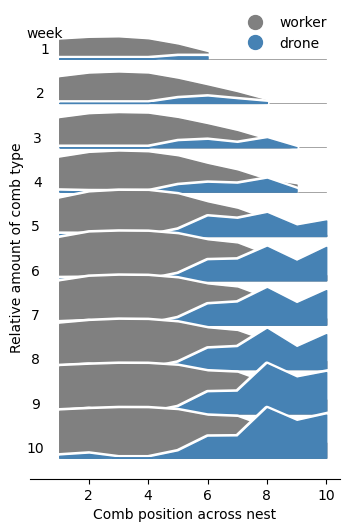

In [63]:
# DRONE AND WORKER COMB DISTRIBUTION
# all DD colonies TOGETHER REORIENTED
# NOT smoothed

# data
smoothnum = 200
yoffset=.9
lw=4
maxweek=11
alpha=1
data = df_mergedinsp[(df_mergedinsp['treatment']=='DD')&
                    (df_mergedinsp['week']<maxweek+1)
                    ].reset_index(drop=True)
data = data[['colony',
                    'week',
                    'frame',
                    'totalworkercomb',
                    'totaldronecomb',
                    'totalcomb'
                    ]]

data['frame_RO'] = 11 - data.frame
data.loc[(data.colony=='DD6')|(data.colony=='DD7'), 'frame_RO'] = data.frame

data = data.drop(columns=['colony'])
data = data.groupby(['week','frame_RO'], as_index=False).mean()


maxworker = np.max(data.totalworkercomb)
maxdrone = np.max(data.totaldronecomb)

# colormap
colormap = 'viridis'
Nmax = np.max(data.week) + 2
Nmin = np.min(data.week) - 2
Nlen = int(Nmax - Nmin)
cmap = matplotlib.cm.get_cmap(colormap, Nlen)
colors = cmap(np.linspace(0, 1, Nlen))

# figure
plt.figure(figsize=(4,6))
for w in range(np.max(data.week)):
    df = data[data['week']==w]
    if len(df)>0:

        # nest edge
        comb_last = 0
        # left edge
        for i in range(len(df)):
            comb = df.totalcomb.iloc[i]
            if (comb > comb_last) & (comb_last < 100):
                nest_edge_L = df.frame_RO.iloc[i]
                break
        # right edge
        comb_last = 0
        for i in range(len(df)-1, -1, -1):
            comb = df.totalcomb.iloc[i]
            if (comb > 100) & (comb_last < 100):
                nest_edge_R = df.frame_RO.iloc[i]
                break
        nest_edges = np.array([nest_edge_L, nest_edge_R])
        df = df[(df.frame_RO>=nest_edges[0])&(df.frame_RO<=nest_edges[1])].reset_index(drop=True)
        x = df.frame_RO

        #baseline
        plt.plot([1,10], [0 - yoffset*w, 0 - yoffset*w], c='grey', lw=.5, zorder=1)

        #worker
        y = np.array(df.totalworkercomb)/maxworker - yoffset*w
        zorder = w*5
        plt.fill_between(x, y, 0 - yoffset*w, alpha=alpha, color='grey', zorder=zorder, interpolate=False)
        plt.plot(x, y, c="w", lw=lw, zorder=zorder-1)

        #drone
        y = np.array(df.totaldronecomb)/maxdrone - yoffset*w
        zorder = w*5+1
        plt.fill_between(x, y, 0 - yoffset*w, alpha=alpha, color='steelblue', zorder=zorder, interpolate=False)
        plt.plot(x, y, c="w", lw=lw, zorder=zorder-1)

        #legend
        legend_elements = [
                        Line2D([0], [0], marker='o', color='grey', label='worker', markersize=10, lw=0),
                        Line2D([0], [0], marker='o', color='steelblue', label='drone', markersize=10, lw=0),
                        ]
        plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1,1.03), frameon=False)
        # plt.text(np.min(x)-np.max(x)*.1, 0 - yoffset*w,"Week " + str(w), zorder=1000)
        if w==1:
            plt.text(np.min(x)-np.max(x)*.08, .1 - yoffset*w, 'week\n' + str(w), zorder=1000, ha='center')
        else:
            plt.text(np.min(x)-np.max(x)*.08, .1 - yoffset*w, str(w), zorder=1000, ha='center')
# plt.title('All DDs')
plt.xlim(np.min(x)-np.max(x)*.1)
plt.xlabel("Comb position across nest")
plt.ylabel("Relative amount of comb type")
plt.yticks([])
# plt.spines['bottom'].set_bounds(1, 10)
plt.xticks(np.arange(2,12,2))
sns.despine(left=True)

# plt.savefig(userpath + 'Ridgeline_AllDDs_WorkerDrone_FrameRO_sm_notsmooth', dpi=300, bbox_inches='tight',)

# Specialization

## Cell Level

In [64]:
maxweek=10
masks = Contents[:6] # all DDs
# masks = Contents[1] # single colony
# masks = Contents[0][:maxweek,9] # single frame side
# figsize=(4,7.5)
figsize=(8,15)

cell_sp = cell_specialists(masks, maxweek=10, prop_thres=None)

# ~ 12s

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%


thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%


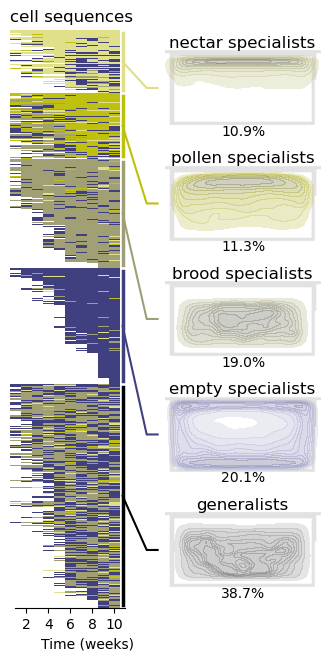

In [65]:
maxweek=10
masks = Contents[:6] # all DDs
figsize=(4,7.5)

cell_sp = cell_specialists(masks, maxweek=10, prop_thres=None)
plot_cell_specialists(cell_sp, figsize=figsize)

# plt.savefig(userpath + 'AvgSTD_Sequence_maxweek'+ str(maxweek) + '_AllDDs_allframes_sm', dpi=300, bbox_inches='tight')

In [67]:
# Stratification
#### ALL DDs STACKED ####

maxweek = 10

# For empty frame to show contents in
frame = Contents[0][4][18]
frame = np.where(frame==1,frame,0)



# SEQUENCES for all DDs
slist=[]
ptlist=[]
zlist=[] # same what frame in the nest
for c in range(6):
    # masks0 = Contents[c][:maxweek,::2] #all timepoints for every other comb side
    masks0 = Contents[c][:maxweek] #all timepoints for every comb side

    # filter out points outside of frame
    masks = np.copy(masks0)
    masks[:,:,:ymincrop,:] = 0
    masks[:,:,ymaxcrop:,:] = 0
    masks[:,:,:,:xmincrop] = 0
    masks[:,:,:,xmaxcrop:] = 0

    for f in range(10):
        # s,pts = get_cell_sequences(masks[:maxweek,f])
        # s = np.where((s>2)&(s<6),5,s) # Simplify brood into single value
        # s = np.where((s==7)|(s==8),7,s) # Simplify nectar and honey into single value
        # s = np.where(s>8,2,s) # Any higher values (qcup or bees) become empty comb
        # slist.extend(s)
        # ptlist.extend(pts)
        # if c>3:
        #     zlist.extend([f]*len(s))
        # else:
        #     zlist.extend([9-f]*len(s))

        for side in range(2): # get both sides of comb
            mask = masks[:maxweek,f*2+side]
            if side == 1:
                mask = np.flip(mask, axis=2)
            s,pts = get_cell_sequences(mask)
            s = np.where((s>2)&(s<6),5,s) # Simplify brood into single value
            s = np.where((s==7)|(s==8),7,s) # Simplify nectar and honey into single value
            s = np.where(s>8,2,s) # Any higher values (qcup or bees) become empty comb
            slist.extend(s)
            ptlist.extend(pts)
            if c>3:
                zlist.extend([f]*len(s))
            else:
                zlist.extend([9-f]*len(s))

slist = np.array(slist)
pts = np.array(ptlist)
zlist = np.array(zlist)


# GET COUNTS AND PROPORTIONS 
counts, proportions = get_counts_and_proportions(slist)
highest_counts = np.max(counts[:,1:], axis=1) # record highest non-zero count for each sequence (for visually sorting the sequences later)


# CALCULATE SPECIALIST THRESHOLDS
prop_means = np.mean(proportions, axis=0)
prop_std = np.std(proportions, axis=0)
prop_thres = prop_means + prop_std # threshold to be classified as specialist: need to spend proportion of time being a content type for more than the mean + 1 st dev for all DD cells


# ASSIGN CLASSIFICATIONS TO EACH CELL
classification_names = ['generalists','empty specialists','brood specialists','pollen specialists','nectar specialists']
classifications=[]
for seq in proportions:
    if seq[0]>prop_thres[0]:
        id = 2 # empty specialist
    elif seq[1]>prop_thres[1]:
        id = 5 # brood specialist
    elif seq[2]>prop_thres[2]:
        id = 6 # pollen specialist
    elif seq[3]>prop_thres[3]:
        id = 7 # nectar speiacialist
    else:
        id = 0 #generalist/mixed use
    classifications.append(id)
classifications = np.array(classifications)

# CALCULATE SPECIALIST PROPORTIONS
ids, idcounts = np.unique(classifications, return_counts=True)
class_props = (idcounts/len(slist))*100



# SORT AND SEPARATE SEQUENCES BY CLASS
sortidx = np.lexsort((highest_counts,classifications))
seq_sorted = slist[sortidx][::-1]
pts_sorted = pts[sortidx][::-1]
z_sorted = zlist[sortidx][::-1]
class_sorted = classifications[sortidx][::-1]

seq_sep=[]
pts_sep=[]
z_sep=[]
counts_sep=[]
props_sep=[]
for i in ids:
    idx = np.argwhere(classifications==i)

    seq = slist[idx]
    seq_sep.append(np.squeeze(seq))

    points = pts[idx]
    pts_sep.append(np.squeeze(points))

    zs = zlist[idx]
    z_sep.append(np.squeeze(zs))

    count = counts[idx]
    counts_sep.append(np.squeeze(count))

    props = proportions[idx]
    props_sep.append(np.squeeze(props))


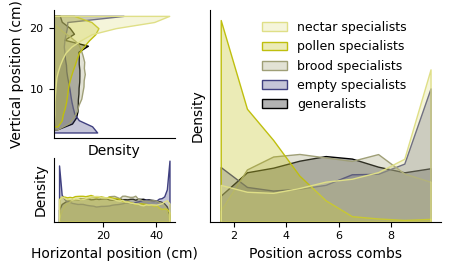

In [68]:
## DDs only ALL 3
# Not Smooth
# ticks and labels

plt.style.use('default')
fig = plt.figure(figsize=(5,2.75), constrained_layout=False)

gs = GridSpec(2, 2, figure=fig, height_ratios=[2,1], width_ratios=[1,1.9], wspace=.2, hspace=.2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[:, 1])

# fig,ax = plt.subplots(2,1, figsize=(5,8), height_ratios=[2,1])

for i in range(len(pts_sep)):
    points = pts_sep[i]
    x = points[:,0]
    y = Contents[0][0][0].shape[0] - points[:,1]
    z = z_sep[i] + 1

    g=sns.histplot(  ax=ax1,
                    y=y*px_to_cm_factor,
                    fill=True,
                    alpha=.3,
                    # bw_adjust=2,
                    color=contenthex[ids[i]],
                    label=classification_names[i],
                    stat='density',
                    element='poly',
                    binwidth=1
                    )
    

    sns.histplot(  ax=ax2,
                    x=x*px_to_cm_factor,
                    fill=True,
                    alpha=.3,
                    # bw_adjust=2,
                    color=contenthex[ids[i]],
                    label=classification_names[i],
                    stat='density',
                    element='poly',
                    binwidth=1
                    )
    sns.histplot(    ax=ax3,
                    x=z,
                    fill=True,
                    alpha=.3,
                    # bw_adjust=2,
                    color=contenthex[ids[i]],
                    label=classification_names[i],
                    stat='density',
                    element='poly',
                    binwidth=1
                    )
# g.invert_yaxis()
ax1.set_xticks([])
# ax1.set_yticks([])
ax1.set_yticklabels((ax1.get_yticks()).astype(int), fontsize=8)
ax1.set_ylabel('Vertical position (cm)')
handles, labels = ax1.get_legend_handles_labels()
ax3.legend(handles[::-1], labels[::-1],loc="upper right", bbox_to_anchor=(.9, 1), frameon=False, fontsize=9)

# ax2.set_xticks([])
ax2.set_xticklabels((ax2.get_xticks()).astype(int), fontsize=8)
ax2.set_yticks([])
ax2.set_xlabel('Horizontal position (cm)')

# ax3.set_xticks([])
ax3.set_xticklabels((ax3.get_xticks()).astype(int), fontsize=8)
ax3.set_yticks([])
ax3.set_xlabel('Position across combs')

sns.despine()

# plt.savefig(userpath + 'AvgSTD_Sequence_maxweek'+ str(maxweek) + '_PositionalStratification_frame_sm_notsmooth', dpi=300, bbox_inches='tight')

#### Randomized nest

In [69]:
# Get observed and randomized colony specialist proportions

# create specialist thresholds based on all DD cells
maxweek = 10
masks = Contents[:6]
specialists = cell_specialists(masks, maxweek=maxweek, prop_thres=None)
prop_thres = specialists.prop_thres

df_class_props=[]
for c in range(6):
    masks = Contents[c]

    # DD
    specialists = cell_specialists(masks, maxweek=maxweek, prop_thres=prop_thres, print_results=False)

    df_temp = pd.DataFrame()
    df_temp['colony'] = [colony_names[c]]*len(specialists.ids)
    df_temp['treatment'] = ['observed']*len(specialists.ids)
    df_temp['specialization'] = specialists.classification_names
    df_temp['class_ids'] = specialists.ids
    df_temp['class_props'] = specialists.class_props
    df_class_props.append(df_temp)

    # randomized DD
    masks_rand = randomize_cells_within_nests(masks, maxweek=maxweek)
    specialists = cell_specialists(masks_rand, maxweek=maxweek, prop_thres=prop_thres, print_results=False)

    df_temp = pd.DataFrame()
    df_temp['colony'] = [colony_names[c]]*len(specialists.ids)
    df_temp['treatment'] = ['randomized']*len(specialists.ids)
    df_temp['specialization'] = specialists.classification_names
    df_temp['class_ids'] = specialists.ids
    df_temp['class_props'] = specialists.class_props
    df_class_props.append(df_temp)

df_class_props = pd.concat(df_class_props, ignore_index=True)
df_class_props.head()

# ~ 30s

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%


,colony,treatment,specialization,class_ids,class_props
0,DD1,observed,generalists,0,42.037024
1,DD1,observed,empty specialists,2,20.534467
2,DD1,observed,brood specialists,5,19.101059
3,DD1,observed,pollen specialists,6,11.438450
4,DD1,observed,nectar specialists,7,6.889001


(0.0, 80.72857006411351)

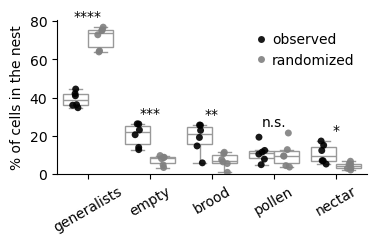

In [70]:
# smaller and flatter

classification_names = ['generalists',
                        'empty',
                        'brood',
                        'pollen',
                        'nectar']
                        
data = df_class_props
x='specialization'
y='class_props'
hue='treatment'

plt.figure(figsize=(4,2))
sns.stripplot(
    data=data, 
    x=x, 
    y=y,
    hue=hue,
    palette=['k', 'grey'],
    dodge=True,  # Use True for categorical dodge
    alpha=0.9,
    )
ax=sns.boxplot(
    data=data, 
    x=x, 
    y=y, 
    hue=hue,
    palette=['w', 'w'],
    showfliers=False,
    legend=False,
    )
sns.despine()

add_sig_note(ax, data, x, y, hue, y_offset=2, method='paired')

plt.legend(frameon=False, handletextpad=-.2)
plt.ylabel('% of cells in the nest')
plt.xlabel('')
plt.xticks(ticks=range(len(classification_names)), labels=classification_names, rotation=30)
plt.ylim(0)

# plt.savefig(userpath + 'AvgSTD_Sequence_maxweek'+ str(maxweek) + '_CompareDDRAND_sm', dpi=300, bbox_inches='tight')

## Comb Level

In [72]:
# COMB SPECIALIZATION
# DDs

masks = Contents[:6]
maxweek=10
cell_sp = cell_specialists(masks, maxweek=10, prop_thres=None)
cell_prop_thres = cell_sp.prop_thres

comb_sp = comb_specialists(masks, maxweek=maxweek, cell_prop_thres=cell_prop_thres, comb_prop_thres=None, print_results=True)

# ~ 35s

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%
comb thresholds: empty specialists = 51.5%; brood specialists = 43.61%; pollen specialists = 30.1%; nectar specialists = 26.48%


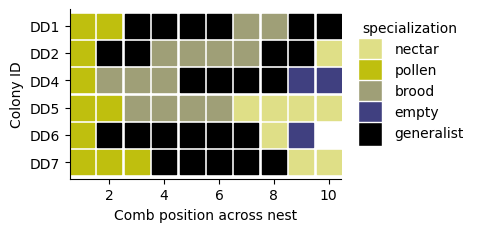

In [73]:
# PLOT
plt.figure(figsize=(3.5,2.2))
for c in range(len(comb_sp.comb_ids)):
    for f in range(len(comb_sp.comb_ids[c])):
        id = comb_sp.comb_ids[c][f]
        x=f+1
        y=len(comb_sp.comb_ids)-(c+1)
        if c==4 and f==9:
            color ='w'
        else:
            color = contenthex[id]
        plt.scatter(x=x, y=y, c=color, s=300, marker='s')

plt.xlabel('Comb position across nest')
plt.ylabel('Colony ID')
plt.yticks(np.arange(len(colony_names[:6])), colony_names[:6][::-1])
plt.ylim(-.6,5.6)
plt.legend(['nectar', 'pollen', 'brood', 'empty', 'generalist'], title='specialization', bbox_to_anchor=(1.5,1), loc='upper right', frameon=False)
ax = plt.gca()
leg = ax.get_legend()
list=[7,6,5,2,0]
for i in range(len(list)):
    leg.legend_handles[i].set_facecolor(contenthex[list[i]])
    leg.legend_handles[i].set_edgecolor('w')
sns.despine()
# plt.savefig(userpath + 'AvgSTD_CombSpecialization_Simple_DD', dpi=300, bbox_inches='tight')

# Shuffled Nest Comparison

## Life stages

In [14]:
# All Life Stages
# SIMPLE BOOTSTAPPING (no hierarchy)

# Bootstrap means and CIs
hierarchy_levels = []   
method = 'mean'
n_bootstraps = 4000
varlist = ['eggs', 'larvae', 'pupae', 'bees_onframe']
count_by = ['colony', 'week']

results=[]
medians=[]
errors=[]
for treat in ['DD', 'SH']:
    t_results=[]
    t_medians=[]
    t_errors=[]
    for content in varlist:
        target = content
        data = df_mergedinsp[(df_mergedinsp['treatment']==treat)
                            &(df_mergedinsp['week']<11)
                            # &(df_mergedinsp['colony']!='SH4') # stopped laying in week 9 and 10)
                            ]
        data = data[np.unique(count_by + [target])]
        data = data.groupby(count_by).sum(numeric_only=True).reset_index()
        bootstrap = hierarchical_bootstrap(data, hierarchy_levels, method=method, n_bootstraps=n_bootstraps)
        sum = bootstrap_summary_stats(bootstrap[target].values)
        t_medians.append(sum['median'])
        t_errors.append(sum['errors'])
        t_results.append(sum)
    medians.append(t_medians)
    errors.append(t_errors)
    results.append(t_results)
results
# ~ 2 min

Bootstrapping: 100%|██████████| 4000/4000 [00:00<00:00, 6713.59it/s]


[[{'median': np.float64(1828.3416666666667),
   'lower_bounds': np.float64(1656.3604166666667),
   'upper_bounds': np.float64(2000.3875),
   'errors': array([171.98125   , 172.04583333])},
  {'median': np.float64(5113.341666666667),
   'lower_bounds': np.float64(4698.444583333333),
   'upper_bounds': np.float64(5521.3625),
   'errors': array([414.89708333, 408.02083333])},
  {'median': np.float64(10119.375),
   'lower_bounds': np.float64(8833.46375),
   'upper_bounds': np.float64(11396.07),
   'errors': array([1285.91125, 1276.695  ])},
  {'median': np.float64(13805.0),
   'lower_bounds': np.float64(12673.291666666668),
   'upper_bounds': np.float64(14988.333333333334),
   'errors': array([1131.70833333, 1183.33333333])}],
 [{'median': np.float64(2520.825),
   'lower_bounds': np.float64(2348.1104166666664),
   'upper_bounds': np.float64(2654.5691666666667),
   'errors': array([172.71458333, 133.74416667])},
  {'median': np.float64(5822.208333333334),
   'lower_bounds': np.float64(5372.

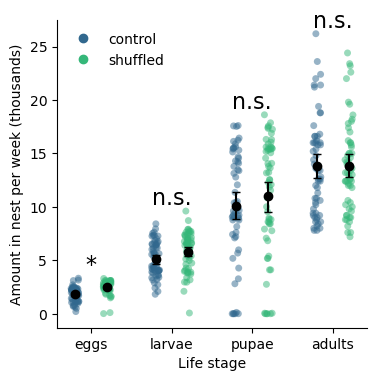

In [15]:
# All Life Stages

# Brood contents
# first 10 weeks
treatlabels = ['control','shuffled']
# sum nest totals per week
data = df_mergedinsp[(~df_mergedinsp.true_week.isin(colony_deadout_week))
                     &(df_mergedinsp['week']<11)
                    #  &(df_mergedinsp['colony']!='SH4') # stopped laying in week 9 and 10)
                     ].groupby(by=['colony','treatment','week','true_week',]).sum(numeric_only=True).reset_index()

varlist = ['eggs', 'larvae', 'pupae', 'bees_onframe']
data = data[['colony','treatment','week','true_week'] + varlist]
data = pd.melt(data, id_vars=['colony','treatment','week','true_week'], value_vars=varlist, var_name='content', value_name='count')

x = 'content'
y = 'count'
hue = 'treatment'
data[y] = data[y]/1000  # Convert to thousands of cells

plt.figure(figsize=(4,4))

# Plot raw data points
sns.stripplot(data=data,
            x=x,
            y=y,
            hue=hue,
            palette=treatmenthex,
            alpha=.5,
            dodge=True,
            zorder=1,
            )
# add_sig_note(ax, data, x=x, y=y, hue=hue, y_offset=.1)

# Bootstrap means and CIs
for i in range(2):
    offset = i*.4 - .2
    plt.errorbar(x=np.arange(len(medians[i]))+offset, 
                y=np.array(medians[i])/1000, 
                yerr=(np.array(errors[i])/1000).T, 
                fmt='o', 
                color='k', 
                capsize=3,
                zorder=10000,
                )

sns.despine()
plt.xlabel('Life stage')
plt.ylabel('Amount in nest per week (thousands)')
plt.xticks(ticks=[0,1,2,3],labels=['eggs', 'larvae', 'pupae', 'adults'])
a = Line2D([], [], color=treatmenthex[0], label=treatlabels[0], marker='o', linestyle='None')
b = Line2D([], [], color=treatmenthex[1], label=treatlabels[1], marker='o', linestyle='None')
plt.legend(handles=[a,b], frameon=False,)

y_offset=.1
hue_order = data[hue].unique()
annotations=['*','n.s.','n.s.','n.s.']

for i, category in enumerate(varlist):
    subset = data[data[x] == category]
    group1 = subset[subset[hue] == hue_order[0]][y]
    group2 = subset[subset[hue] == hue_order[1]][y]
    y_max = max(group1.max(), group2.max())
    plt.text(category, y_max + y_offset, annotations[i], ha='center', va='bottom', color='black', fontsize=16)

# plt.savefig(userpath + 'CompareDDSH_10Weeks_Brood_ADULTS_bootstrapping.png', dpi=300, bbox_inches='tight')

## Brood survival

In [26]:
maxweek=10
side='a'
appended=[]

for c in range(12):
    for w in range(maxweek-1):
        for f in range(20):

            mask0 = Contents[c][w][f]
            mask1 = Contents[c][w+1][f]

            mask0 = np.where(mask0<2,0,mask0) # keep only empty, eggs, larvae
            mask0 = np.where(mask0>4,0,mask0) # keep only empty, eggs, larvae
            mask1 = np.where(mask0>0,mask1,0) # keep only where mask0 was empty, eggs, larvae
            mask0 = np.where((mask0==2) & (mask1<3),0,mask0) # drop where empty stays empty or becomes wood/background
            mask0 = np.where((mask0==2) & (mask1>5),0,mask0) # drop where empty became pollen/nectar/honey
            coords = np.argwhere(mask0>0)

            sources=[]
            targets=[]
            for i in coords:
                source = mask0[i[0]][i[1]]
                target = mask1[i[0]][i[1]]
                sources.append(source)
                targets.append(target)


            temp = pd.DataFrame()
            temp['colony'] = [colony_names[c]]*len(sources)
            temp['treatment'] = [colony_names[c][:2]]*len(sources)
            temp['week'] = [w+1]*len(sources)
            temp['frame'] = [int(f/2)+1]*len(sources)
            temp['side'] = [side]*len(sources)
            temp['source'] = sources
            temp['target'] = targets
            temp['source_name'] = np.take(content_names, sources)
            temp['target_name'] = np.take(content_names, targets)

            appended.append(temp)

            if side=='a':
                side='b'
            else:
                side='a'
df_broodflow = pd.concat(appended).reset_index(drop=True)

df_broodflow

# ~20s

,colony,treatment,week,frame,side,source,target,source_name,target_name
0,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae
1,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae
2,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae
3,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae
4,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae
...,...,...,...,...,...,...,...,...,...
1360855,SH7,SH,9.0,10.0,b,2.0,5.0,empty_comb,pupae
1360856,SH7,SH,9.0,10.0,b,2.0,4.0,empty_comb,larvae
1360857,SH7,SH,9.0,10.0,b,2.0,5.0,empty_comb,pupae
1360858,SH7,SH,9.0,10.0,b,2.0,5.0,empty_comb,pupae


In [27]:
df_broodflow['target_outcome'] = df_broodflow['target_name']
df_broodflow.loc[df_broodflow['target'] > 5, 'target_outcome'] = 'failed'
df_broodflow.loc[df_broodflow['target'] < 3, 'target_outcome'] = 'failed'
df_broodflow.loc[(df_broodflow['source']==3) & (df_broodflow['target']==3), 'target_outcome'] = 'failed'
df_broodflow.loc[(df_broodflow['source']==4) & (df_broodflow['target']==3), 'target_outcome'] = 'failed'
# df_broodflow.loc[(df_broodflow['source']==3) & (df_broodflow['target_outcome']=='failed'), 'target_outcome'] = 'failed_eggs'
# df_broodflow.loc[(df_broodflow['source']==4) & (df_broodflow['target_outcome']=='failed'), 'target_outcome'] = 'failed_larvae'
df_broodflow['outcome'] = df_broodflow['target']
df_broodflow.loc[df_broodflow['target_outcome'] == 'failed', 'outcome'] = 0
df_broodflow

,colony,treatment,week,frame,side,source,target,source_name,target_name,target_outcome,outcome
0,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae,larvae,4.0
1,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae,larvae,4.0
2,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae,larvae,4.0
3,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae,larvae,4.0
4,DD1,DD,1.0,5.0,a,2.0,4.0,empty_comb,larvae,larvae,4.0
...,...,...,...,...,...,...,...,...,...,...,...
1360855,SH7,SH,9.0,10.0,b,2.0,5.0,empty_comb,pupae,pupae,5.0
1360856,SH7,SH,9.0,10.0,b,2.0,4.0,empty_comb,larvae,larvae,4.0
1360857,SH7,SH,9.0,10.0,b,2.0,5.0,empty_comb,pupae,pupae,5.0
1360858,SH7,SH,9.0,10.0,b,2.0,5.0,empty_comb,pupae,pupae,5.0


In [28]:
df_sum = df_broodflow.groupby(['colony', 'treatment', "source_name", "target_outcome"]).size().reset_index(name="value")
df_sum['transition'] = df_sum['source_name'] + '_' + df_sum['target_outcome']
df_sum

,colony,treatment,source_name,target_outcome,value,transition
0,DD1,DD,eggs,failed,3354,eggs_failed
1,DD1,DD,eggs,larvae,4858,eggs_larvae
2,DD1,DD,eggs,pupae,8545,eggs_pupae
3,DD1,DD,empty_comb,eggs,3142,empty_comb_eggs
4,DD1,DD,empty_comb,larvae,26678,empty_comb_larvae
...,...,...,...,...,...,...
103,SH7,SH,empty_comb,larvae,27049,empty_comb_larvae
104,SH7,SH,empty_comb,pupae,20068,empty_comb_pupae
105,SH7,SH,larvae,failed,7086,larvae_failed
106,SH7,SH,larvae,larvae,883,larvae_larvae


[Text(0, 0, 'cont'), Text(1, 0, 'shuf')]

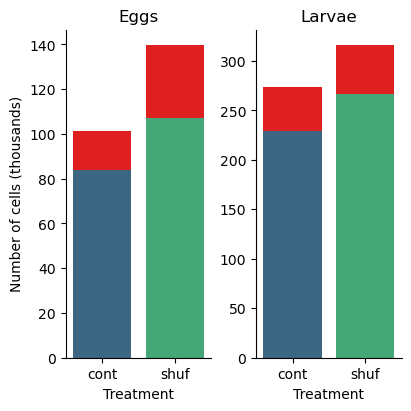

In [29]:
# avg across colonies, totaled over 10 weeks

fig,ax = plt.subplots(1,2,figsize=(4,4), constrained_layout=True)

treatlabels = ['control', 'shuffle']

# EGGS #

data = df_sum[(df_sum['transition']=='eggs_failed')
              |(df_sum['transition']=='eggs_larvae')
              |(df_sum['transition']=='eggs_pupae')]
data.loc[data['transition']=='eggs_larvae', 'target_outcome'] = 'succeeded'
data.loc[data['transition']=='eggs_pupae', 'target_outcome'] = 'succeeded'

df_totals = data.groupby(['treatment']).sum(numeric_only=True).reset_index()
df_outcomes = data.groupby(['treatment', 'target_outcome']).sum(numeric_only=True).reset_index()

sns.barplot(ax=ax[0],
              data=df_totals,
              x='treatment',
              y=df_totals['value']/1000,
              color='red',
              )
df=df_outcomes[df_outcomes['target_outcome']=='succeeded']
sns.barplot(ax=ax[0],
              data=df,
              x='treatment',
              y=df['value']/1000,
              palette=treatmenthex,
            #   palette='viridis',
              )
sns.despine()
ax[0].set_ylabel('Number of cells (thousands)')
ax[0].set_xlabel('Treatment')
ax[0].set_title('Eggs')
ax[0].set_xticklabels(['cont', 'shuf'])


# LARVAE #

data = df_sum[(df_sum['transition']=='larvae_failed')
              |(df_sum['transition']=='larvae_larvae')
              |(df_sum['transition']=='larvae_pupae')]
data.loc[data['transition']=='larvae_larvae', 'target_outcome'] = 'succeeded'
data.loc[data['transition']=='larvae_pupae', 'target_outcome'] = 'succeeded'

df_totals = data.groupby(['treatment']).sum(numeric_only=True).reset_index()
df_outcomes = data.groupby(['treatment', 'target_outcome']).sum(numeric_only=True).reset_index()

sns.barplot(ax=ax[1],
              data=df_totals,
              x='treatment',
              y=df_totals['value']/1000,
              color='red',
              )
df=df_outcomes[df_outcomes['target_outcome']=='succeeded']
sns.barplot(ax=ax[1],
              data=df,
              x='treatment',
              y=df['value']/1000,
              palette=treatmenthex,
            #   palette='viridis',
              )
sns.despine()
ax[1].set_ylabel('')
ax[1].set_xlabel('Treatment')
ax[1].set_title('Larvae')
ax[1].set_xticklabels(['cont', 'shuf'])

# plt.savefig(userpath + 'EggsLarvaeCount_Matchstick.png', dpi=300, bbox_inches='tight')

## Content fluxuations

In [34]:
# CONTENT FLUCTUATIONS

df_mergedinsp=df_mergedinsp.sort_values(by=['colony','frame','side','week']).reset_index(drop=True)

df_mergedinsp['ttl_abs_change'] = 0
for content in content_names[3:9]:
    df_mergedinsp[content + '_change'] = df_mergedinsp[content] - df_mergedinsp[content].shift(+1)
    df_mergedinsp.loc[df_mergedinsp.week == 1, content + '_change'] = np.nan

    df_mergedinsp[content + '_change_perc'] = round(df_mergedinsp[content + '_change'] / df_mergedinsp[content].shift(+1),2)*100
    df_mergedinsp.loc[df_mergedinsp.week == 1, content + '_change_perc'] = np.nan


    df_mergedinsp['perc_' + content + '_change'] = df_mergedinsp['perc_' + content] - df_mergedinsp['perc_' + content].shift(+1)
    df_mergedinsp.loc[df_mergedinsp.week == 1, 'perc_eggs_change'] = np.nan

    df_mergedinsp['perc_' + content + '_change_perc'] = round(df_mergedinsp['perc_' + content + '_change'] / df_mergedinsp['perc_' + content].shift(+1),2)*100
    df_mergedinsp.loc[df_mergedinsp.week == 1, 'perc_' + content + '_change_perc'] = np.nan

    df_mergedinsp['ttl_abs_change'] = df_mergedinsp['ttl_abs_change'] + abs(df_mergedinsp[content + '_change'])

df_mergedinsp['perc_ttl_abs_change'] = (df_mergedinsp['ttl_abs_change']/df_mergedinsp['totalcomb'])*100

df_mergedinsp

,colony,date,week,true_week,frame,side,treatment,background,wood,empty_comb,eggs,larvae,pupae,pollen,nectar,honey,queen_cup,queen_cell,bees,all_comb_centroidX,all_comb_centroidY,empty_comb_centroidX,empty_comb_centroidY,eggs_centroidX,eggs_centroidY,larvae_centroidX,larvae_centroidY,pupae_centroidX,pupae_centroidY,pollen_centroidX,pollen_centroidY,nectar_centroidX,nectar_centroidY,honey_centroidX,honey_centroidY,nectar_honey,totalcomb,perc_empty_comb,perc_eggs,perc_larvae,perc_pupae,perc_pollen,perc_nectar,perc_honey,perc_allbrood,perc_nectar_honey,primary_content,perc_primary_content,primary_content_combinebrood,perc_primary_content_combinebrood,worker_empty_comb,worker_eggs,worker_larvae,worker_pupae,worker_pollen,worker_nectar,worker_honey,drone_empty_comb,drone_eggs,drone_larvae,drone_pupae,drone_pollen,drone_nectar,drone_honey,worker_empty_comb_centroidX,worker_empty_comb_centroidY,worker_eggs_centroidX,worker_eggs_centroidY,worker_larvae_centroidX,worker_larvae_centroidY,worker_pupae_centroidX,worker_pupae_centroidY,worker_pollen_centroidX,worker_pollen_centroidY,worker_nectar_centroidX,worker_nectar_centroidY,worker_honey_centroidX,worker_honey_centroidY,queen_cup_centroidX,queen_cup_centroidY,queen_cell_centroidX,queen_cell_centroidY,bees_centroidX,bees_centroidY,drone_empty_comb_centroidX,drone_empty_comb_centroidY,drone_eggs_centroidX,drone_eggs_centroidY,drone_larvae_centroidX,drone_larvae_centroidY,drone_pupae_centroidX,drone_pupae_centroidY,drone_pollen_centroidX,drone_pollen_centroidY,drone_nectar_centroidX,drone_nectar_centroidY,drone_honey_centroidX,drone_honey_centroidY,worker_allbrood,drone_allbrood,allbrood,totalworkercomb,totaldronecomb,perc_totalworkercomb,perc_totaldronecomb,perc_worker_allbrood,perc_worker_eggs,perc_worker_larvae,perc_worker_pupae,perc_worker_pollen,perc_worker_nectar,perc_worker_honey,perc_drone_allbrood,perc_drone_eggs,perc_drone_larvae,perc_drone_pupae,perc_drone_pollen,perc_drone_nectar,perc_drone_honey,perc_dronebrood_allbrood,primary_content_combtypes,perc_primary_content_combtypes,primary_content_combinebrood_combtypes,perc_primary_content_combinebrood_combtypes,empty_space,date_formatted,filename,exp_date,ncombs,centX,centY,rmaxid,rmaxpos,rmax,width,cmaxid,cmaxpos,cmax,height,aspecthw,perim,area,perarea,centX2,centY2,rmaxid2,rmaxpos2,rmax2,width2,cmaxid2,cmaxpos2,cmax2,height2,aspecthw2,perim2,area2,perarea2,areagrowth,area2growth,QR,position,invert_frame,bees_sum,comb_sq,comb_sum,comb_cm2,core_position,frame_unique,bees_onframe,bees_sum_perweek,first_comb_frame,bees_percombcm2,combcm2_perbee,nframes_with_comb,comb_birthday,comb_age,comb_sum_perweek,avg_comb_perframe,comb_prop_ttl,birthday_nestsize,nestarea_seasontotal,prop_area_seasontotal,comb_growth,combcm2_growth,comb_growth_prop,combcm2_lastweek,emptyspace_onframe,framesfromfirst,initial_region,comb_cm2_neibL,comb_cm2_neibR,comb_cm2_neib_avg,bees_neibL,bees_neibR,bees_neib_avg,n_comb_neibs,2_comb_neibs,bi_2_comb_neibs,nest_edge,nest_edge_triplet,last_pos,next_pos,last_neibR,last_neibR_combcm2,last_neibL,last_neibL_combcm2,last_neibBigger_comb,last_neibSmaller_comb,last_neib_combavg,this_neibR,this_neibR_combcm2,this_neibL,this_neibL_combcm2,this_neibBigger_comb,this_neibSmaller_comb,this_neib_combavg,neighborhood_change,next_neibR,next_neibR_combcm2,next_neibL,next_neibL_combcm2,next_neibBigger_comb,next_neibSmaller_comb,next_neib_combavg,days_since_last_insp,nestheight,nestheight2,nestheightperc,nestwidth,nestwidth2,nestwidthperc,frameaspecthw,nestaspecthw,nestdepth,nestdepthperc,nestarea,nestarea2,nestareaperc,nestareagrowth,nestarea2growth,nestcentX,nestcentX2,nestcentY,nestcentY2,rmaxsum,nestcentZprep,Zweight,nestcentZ,initialN,initialE,initialQ,initialQl,comb_width,comb_height,comb_perim,comb_aspecthw,seasonal_phase,seasonal_phase_num,total_area,number_of_patches,patch_density,largest_patch_index,total_edge,edge_density,total_core_area,number_of_disjunct_core_areas,landscape_shape_index,effective_mesh_size,entropy,shann

In [37]:
# Bootstrap means and CIs
# NUMBER OF FLUCTUATIONS

hierarchy_levels = ['colony']   
method = 'mean'
n_bootstraps = 4000
varlist = ['ttl_abs_change']
count_by = []

results=[]
medians=[]
errors=[]
for treat in ['DD', 'SH']:
    t_results=[]
    t_medians=[]
    t_errors=[]
    for content in varlist:
        target = content
        data = df_mergedinsp[(df_mergedinsp['treatment']==treat)&
                     (df_mergedinsp['week']<11)&
                     (df_mergedinsp['totalworkercomb']>200)]
        # data = data[np.unique(count_by + [target])]
        data = data[hierarchy_levels + [target]]
        # data = data.groupby(count_by).sum(numeric_only=True).reset_index()
        bootstrap = hierarchical_bootstrap(data, hierarchy_levels, method=method, n_bootstraps=n_bootstraps)
        sum = bootstrap_summary_stats(bootstrap[target].values)
        t_medians.append(sum['median'])
        t_errors.append(sum['errors'])
        t_results.append(sum)
    medians.append(t_medians)
    errors.append(t_errors)
    results.append(t_results)
results

Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 2415.92it/s]


[[{'median': np.float64(857.5727426906419),
   'lower_bounds': np.float64(752.0302076240102),
   'upper_bounds': np.float64(967.1159609056522),
   'errors': array([105.54253507, 109.54321822])}],
 [{'median': np.float64(1222.1505298112934),
   'lower_bounds': np.float64(1084.1730838000242),
   'upper_bounds': np.float64(1354.5134905076022),
   'errors': array([137.97744601, 132.3629607 ])}]]

In [38]:
# Bootstrap means and CIs
# PERCENT OF COMB THAT CHANGED

hierarchy_levels = ['colony']   
method = 'mean'
n_bootstraps = 4000
varlist = ['perc_ttl_abs_change']
count_by = []

results=[]
medians=[]
errors=[]
for treat in ['DD', 'SH']:
    t_results=[]
    t_medians=[]
    t_errors=[]
    for content in varlist:
        target = content
        data = df_mergedinsp[(df_mergedinsp['treatment']==treat)&
                     (df_mergedinsp['week']<11)&
                     (df_mergedinsp['totalworkercomb']>200)]
        # data = data[np.unique(count_by + [target])]
        data = data[hierarchy_levels + [target]]
        # data = data.groupby(count_by).sum(numeric_only=True).reset_index()
        bootstrap = hierarchical_bootstrap(data, hierarchy_levels, method=method, n_bootstraps=n_bootstraps)
        sum = bootstrap_summary_stats(bootstrap[target].values)
        t_medians.append(sum['median'])
        t_errors.append(sum['errors'])
        t_results.append(sum)
    medians.append(t_medians)
    errors.append(t_errors)
    results.append(t_results)
results

Bootstrapping: 100%|██████████| 4000/4000 [00:01<00:00, 2110.11it/s]


[[{'median': np.float64(32.75767467776137),
   'lower_bounds': np.float64(29.68537515178082),
   'upper_bounds': np.float64(36.17533757716874),
   'errors': array([3.07229953, 3.4176629 ])}],
 [{'median': np.float64(46.94690152470778),
   'lower_bounds': np.float64(42.84116528836316),
   'upper_bounds': np.float64(50.41250419704362),
   'errors': array([4.10573624, 3.46560267])}]]

In [39]:
# means from data

data = df_mergedinsp[(df_mergedinsp['week']>1)&
                     (df_mergedinsp['week']<11)&
                     (df_mergedinsp['totalworkercomb']>200)]
data.groupby('treatment').agg({'perc_ttl_abs_change':'mean'}).reset_index()

,treatment,perc_ttl_abs_change
0,DD,32.770504
1,SH,46.869965


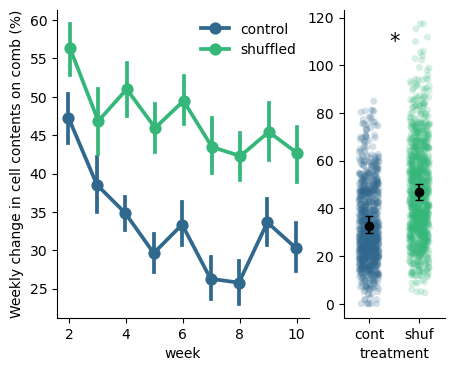

In [40]:
data = df_mergedinsp[(df_mergedinsp['week']>1)&
                     (df_mergedinsp['week']<11)&
                     (df_mergedinsp['totalworkercomb']>200)]
# replace treatment codes with full names
data['treatment'] = data['treatment'].replace({'DD':'control', 'SH':'shuffled'})

fig,ax = plt.subplots(1,2,figsize=(5,4), width_ratios=[2.5,1], sharey=False)

sns.pointplot(ax=ax[0],
              data=data,
              y=data['perc_ttl_abs_change'],
              x='week',
              hue='treatment',
              palette='viridis',
              dodge=True,
              native_scale=True,
              )
ax[0].legend(frameon=False)
ax[0].set_ylabel('Weekly change in cell contents on comb (%)')

sns.stripplot(ax=ax[1],
              data=data,
              y=data['perc_ttl_abs_change'],
              x='treatment',
              palette='viridis',
              jitter=0.2,
              alpha=.2,)
means = data.groupby('treatment').agg({'perc_ttl_abs_change':'mean'}).reset_index()
ax[1].errorbar(x=np.arange(len(means)), 
             y=means['perc_ttl_abs_change'], 
             yerr=np.array(errors).squeeze(), 
             fmt='o', 
             color='k', 
             capsize=3,
             zorder=1000000)
ax[1].set_ylabel('')
ax[1].set_xticklabels(['cont', 'shuf'])
ax[1].set_xlim(-0.5,1.5)
# Add an asterisk for significance
ax[1].text(0.5, max(data['perc_ttl_abs_change'])*.9, '*', ha='center', va='bottom', fontsize=15)
sns.despine()

# plt.savefig(userpath + 'CompareDDSH_PerAbsChangeCellContents_Bootstrap.png', dpi=300, bbox_inches='tight')

## Nest level distributions

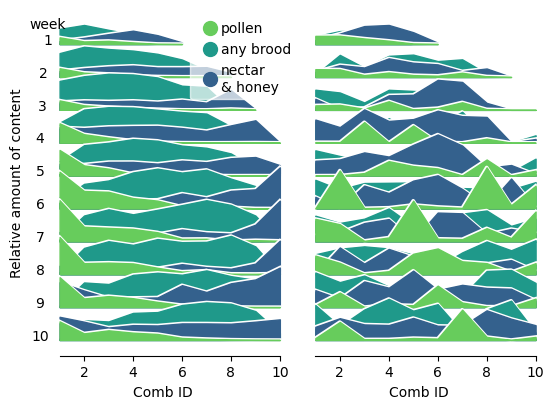

In [41]:
# COMPARE DD AND SH EXAMPLE COLONIES
# 1 row 2 cols
# NOT smoothed

# Simplified contents

# data
smoothnum = 200
yoffset=.8
lw=2.5
maxweek=11
alpha=1

colonies = [1,6]  # DD2 and SH2

fig,ax = plt.subplots(1,2, figsize=(6.6,4.5))

for c in range(2):  # DD2 and SH2
    data = df_mergedinsp[(df_mergedinsp['colony']==colony_names[colonies[c]])&
                        (df_mergedinsp['week']<maxweek+1)
                        ].reset_index(drop=True)
    data = data[['colony',
                        'week',
                        'frame',
                        'pollen',
                        'nectar_honey',
                        'allbrood',
                        'totalcomb'
                        ]]
    data = data.groupby(['colony','week','frame'], as_index=False).mean()

    maxpupae = np.max(data.allbrood)
    maxpollen = np.max(data.pollen)
    maxnectar = np.max(data.nectar_honey)

    # colormap
    colormap = 'viridis'
    Nmax = np.max(data.week) + 2
    Nmin = np.min(data.week) - 2
    Nlen = int(Nmax - Nmin)
    cmap = matplotlib.cm.get_cmap(colormap, Nlen)
    colors = cmap(np.linspace(0, 1, Nlen))

    # figure
    for w in range(np.max(data.week)):
        df = data[data['week']==w]
        if len(df)>0:

            # nest edge
            comb_last = 0
            # left edge
            for i in range(len(df)):
                comb = df.totalcomb.iloc[i]
                if (comb > comb_last) & (comb_last < 100):
                    nest_edge_L = df.frame.iloc[i]
                    break
            # right edge
            comb_last = 0
            for i in range(len(df)-1, -1, -1):
                comb = df.totalcomb.iloc[i]
                if (comb > 100) & (comb_last < 100):
                    nest_edge_R = df.frame.iloc[i]
                    break
            nest_edges = np.array([nest_edge_L, nest_edge_R])
            df = df[(df.frame>=nest_edges[0])&(df.frame<=nest_edges[1])].reset_index(drop=True)

            x = 11 - np.array(df.frame)
            nest_edges = 11-nest_edges
            if (colony_names[c]=='DD6')|(colony_names[c]=='DD7'):
                x = 11 - x
                nest_edges = 11-nest_edges

            #pupae
            y = np.array(df.allbrood)/maxpupae - yoffset*w
            zorder = w*5
            ax[c].fill_between(x, y, 0 - yoffset*w, alpha=alpha, color=colors[7], zorder=zorder, interpolate=False)
            ax[c].plot(x, y, c="w", lw=lw, zorder=zorder-1)

            #nectar
            y = np.array(df.nectar_honey)/maxnectar - yoffset*w
            zorder = w*5+1
            ax[c].fill_between(x, y, 0 - yoffset*w, alpha=alpha, color=colors[4], zorder=zorder, interpolate=False)
            ax[c].plot(x, y, c="w", lw=lw, zorder=zorder-1)

            #pollen
            y = np.array(df.pollen)/maxpollen - yoffset*w
            zorder = w*5+2
            ax[c].fill_between(x, y, 0 - yoffset*w, alpha=alpha, color=colors[10], zorder=zorder, interpolate=False)
            ax[c].plot(x, y, c="w", lw=lw, zorder=zorder-1)

            #legend
            if c==0:
                legend_elements = [Line2D([0], [0], marker='o', color=colors[10], label='pollen', markersize=10, lw=0),
                                Line2D([0], [0], marker='o', color=colors[7], label='any brood', markersize=10, lw=0),
                                Line2D([0], [0], marker='o', color=colors[4], label='nectar\n& honey', markersize=10, lw=0),
                                ]
                ax[c].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.05,1), edgecolor='w', facecolor='w', framealpha=.7, handletextpad=-.2).set_zorder(1000)
            if (c==0)|(c==2)|(c==4):
                if w==1:
                    ax[c].text(np.min(x)-np.max(x)*.08, 0 - yoffset*w, 'week\n' + str(w), zorder=1000, ha='center')
                else:
                    ax[c].text(np.min(x)-np.max(x)*.08, 0 - yoffset*w, str(w), zorder=1000, ha='center')
    ax[c].set_xlim(np.min(x)-np.max(x)*.1)

    ax[c].set_xlabel("Comb ID")
    ax[c].spines[['left','right','top']].set_visible(False)
    ax[c].spines['bottom'].set_bounds(1, 10)
    ax[c].set_xticks(np.arange(2,12,2))
    # else:
    #     ax[c].set_xticks([])
    #     ax[c].spines[['bottom','left','right','top']].set_visible(False)
    if (c==0)|(c==2)|(c==4):
        ax[c].set_ylabel("Relative amount of content", labelpad=8)
    ax[c].set_yticks([])
plt.subplots_adjust(wspace=0, hspace=0)
plt.savefig(userpath + 'Ridgeline_SHDDs_Composite_ROSM_EXAMPLEs_notsmooth.png', dpi=300, bbox_inches='tight',)

## Specialization

In [74]:
# COMB SPECIALIZATION
# DDs and SHs

masks = Contents[:6]
maxweek=10
#get cell thres
cell_sp = cell_specialists(masks, maxweek=10, prop_thres=None)
cell_prop_thres = cell_sp.prop_thres
#get comb thres
comb_sp = comb_specialists(masks, maxweek=maxweek, cell_prop_thres=cell_prop_thres, comb_prop_thres=None, print_results=True)
comb_prop_thres = comb_sp.comb_prop_thres

# get specializations
masks = Contents
comb_sp = comb_specialists(masks, maxweek=maxweek, cell_prop_thres=cell_prop_thres, comb_prop_thres=comb_prop_thres, print_results=True)

# ~ 33s

thresholds: empty specialists = 74.72%; brood specialists = 68.48%; pollen specialists = 24.96%; nectar specialists = 35.23%
proportions: generalists = 38.73%; empty specialists = 20.05%; brood specialists = 18.97%; pollen specialists = 11.35%; nectar specialists = 10.9%
comb thresholds: empty specialists = 51.5%; brood specialists = 43.61%; pollen specialists = 30.1%; nectar specialists = 26.48%
comb thresholds: empty specialists = 51.5%; brood specialists = 43.61%; pollen specialists = 30.1%; nectar specialists = 26.48%


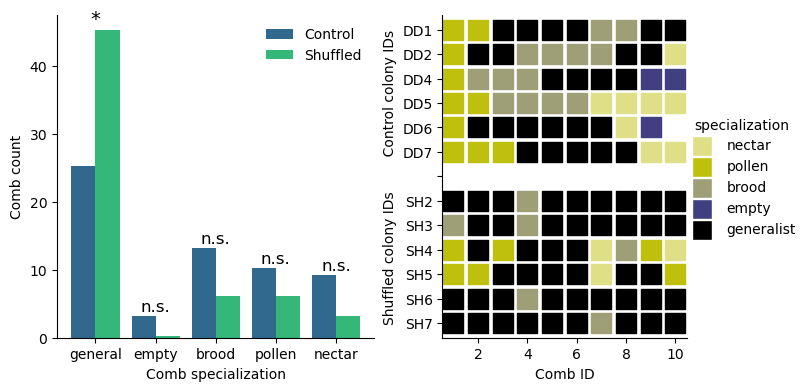

In [76]:
# COMBINE SIMPLE AND COUNTS
# FLIPPED

fig,ax = plt.subplots(1,2,figsize=(8,3.8), width_ratios=[1.3,1], constrained_layout=True)
# fig.tight_layout(w_pad=1)

# PLOT COUNTS
categories = [0,2,5,6,7]

DDcounts=[]
SHcounts=[]
for id in categories:
    DDcounts.append(np.count_nonzero(comb_sp.comb_ids[:6]==id))
    SHcounts.append(np.count_nonzero(comb_sp.comb_ids[6:]==id))

classification_names = ['general',
                        'empty',
                        'brood',
                        'pollen',
                        'nectar']

# create data 
x = np.arange(len(classification_names))
y1 = np.array(DDcounts) + .2
y2 = np.array(SHcounts) + .2
width = 0.40
  
# plot data in grouped manner of bar type 
ax[0].bar(x-0.2, y1, width, color=treatmenthex[0], alpha=1) 
ax[0].bar(x+0.2, y2, width, color=treatmenthex[1], alpha=1) 
ax[0].set_xticks(x)
ax[0].set_xticklabels(classification_names)
ax[0].set_xlabel('Comb specialization')
ax[0].set_ylabel('Comb count')
ax[0].legend(["Control", "Shuffled"], frameon=False) 

# binomial tests for each dd-sh pair
from scipy.stats import binomtest
for i in range(len(classification_names)):
    dd_count = DDcounts[i]
    sh_count = SHcounts[i]
    total_count = dd_count + sh_count
    result = binomtest(dd_count, n=total_count, p=0.5)
    if result.pvalue < 0.05:
        ax[0].text(x[i], max(dd_count, sh_count)+.5, '*', ha='center', va='bottom', fontsize=14)
    else:
        ax[0].text(x[i], max(dd_count, sh_count)+.5, 'n.s.', ha='center', va='bottom', fontsize=12)

# COMB SPECIALIST LOCATIONS
for c in range(len(comb_sp.comb_ids)):
    for f in range(len(comb_sp.comb_ids[c])):
        id = comb_sp.comb_ids[c][f]
        x=f+1
        if c>5:
            y=13-(c+1)
        else:
            y=13-c
        if c==4 and f==9:
            color ='w'
        else:
            color = contenthex[id]
        ax[1].scatter(x=x, y=y, c=color, s=210, marker='s')

ax[1].set_xlabel('Comb ID')
ax[1].set_ylabel('Shuffled colony IDs        Control colony IDs')
ax[1].set_yticks(np.arange(1,14))
ax[1].set_yticklabels(np.concatenate((colony_names[:6], [''], colony_names[6:]))[::-1])
ax[1].legend(['nectar', 'pollen', 'brood', 'empty', 'generalist'], title='specialization', bbox_to_anchor=(1.5,.72), loc='upper right', frameon=False)
leg = ax[1].get_legend()
list=[7,6,5,2,0]
for i in range(len(list)):
    leg.legend_handles[i].set_facecolor(contenthex[list[i]])
    leg.legend_handles[i].set_edgecolor('w')

sns.despine()

# plt.savefig(userpath + 'AvgSTD_CombSpecialization_Counts_Combined_flip', dpi=300, bbox_inches='tight')